# Backtest: fees and risk

In [1]:
from pathlib import Path
import json, hashlib, re, zipfile, shutil, time, platform, ast, os
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit
from numba import njit
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

ROOT=Path.cwd()
OUT=ROOT/'artifacts/research_54/backtest'
for folder in [OUT,OUT/'inputs',OUT/'decisions',OUT/'trades',OUT/'figures']:
    folder.mkdir(parents=True,exist_ok=True)
FEATURE_MANIFEST=ROOT/'artifacts/research_54/statistics/manifest.json'
manifest=json.loads(FEATURE_MANIFEST.read_text())
files=manifest['files']; assert len(files)==54
SPLIT=pd.Timestamp('2020-01-01'); END=pd.Timestamp('2021-10-18 23:59:59')
MODEL_DIR=ROOT/'artifacts/research_54/models'
SOURCE_WORKBOOK=Path(os.environ['MFT_FEE_WORKBOOK']) if os.environ.get('MFT_FEE_WORKBOOK') else None
WORKBOOK=OUT/'inputs/commission_schedule.xlsx'
if not WORKBOOK.exists():
    if SOURCE_WORKBOOK is None or not SOURCE_WORKBOOK.is_file():
        raise FileNotFoundError("Bundled commission_schedule.xlsx is missing; set MFT_FEE_WORKBOOK to the source workbook.")
    shutil.copy2(SOURCE_WORKBOOK,WORKBOOK)

# Required choices: None means unknown, never zero.
RATIO_DIVISOR=10000               # Workbook Notes; explicit per-symbol reconciliation below
RATIO_DIVISOR_BY_SYMBOL={k:1000 for k in ['RB','HC','AG','FU','JD','UR']}
FEE_PERIOD_MODE='fixed_2026_scenario'                # 'fixed_2026_scenario' or dated historical schedule
BROKER_CNY_PER_LOT_SIDE=0.
SLIPPAGE_BPS_PER_SIDE=0.          # Includes spread/impact only if explicitly specified
AG_RATE_POLICY='far_month_base'                # 'far_month_base' / 'near_month_all' / explicit dated schedule
RUN_BACKTEST=True                  # Exchange-only fixed Excel scenario, with explicit source caveats

TARGET_VOL=.001; MAX_LEVERAGE=3.; MIN_VOL_FLOOR=1e-5
MIN_DIRECTION_ROWS=1000; EGARCH_SIMULATIONS=2048; RANDOM_SEED=42
EXPANSION_WINDOW=30; EXPANSION_MIN_PERIODS=15; BREAKOUT_WINDOW=20
VOLATILITY_NAMES=['V1_GARCH','V2_EGARCH','V3_GJR_GARCH']
DIRECTION_NAMES=['D0_Momentum5','D1_Raw_ARMA','D2_GARCH_ARMA','D2_EGARCH_ARMA','D2_GJR_ARMA','D3_Logistic_Core','D3_Logistic_Asymmetric']
ARMA_CANDIDATES=[(1,0),(2,0),(1,1)]
RULE_NAMES=['return_high_volume','return_low_volume','range_high_volume','range_low_volume','return_high_volatility','return_low_volatility','normalized_return']
EXCHANGE_MAP={'XSGE':'SHFE','XZCE':'CZCE','XDCE':'DCE','XINE':'INE','CCFX':'CFFEX'}
MULTIPLIERS=dict(RB=10,I=100,SC=1000,NI=1,J=100,RU=10,IF=300,AU=1000,CU=5,AG=15,IC=200,M=10,P=10,T=10000,ZN=5,Y=10,TA=5,MA=10,SR=10,AP=10,CF=5,PP=5,RM=10,BU=10,HC=10,OI=10,IH=300,EG=10,JM=60,FU=10,L=5,SA=20,ZC=100,AL=5,FG=20,SP=10,TF=10000,C=10,V=5,JD=10,EB=5,A=10,CJ=5,SM=5,SN=1,CS=10,SS=5,SF=5,PB=5,UR=20,B=10,NR=10,CY=5,RR=10)

def digest(path):
    with Path(path).open('rb') as handle: return hashlib.file_digest(handle,'sha256').hexdigest()
def safe_json(value):
    if isinstance(value,dict): return {str(k):safe_json(v) for k,v in value.items()}
    if isinstance(value,(list,tuple,np.ndarray)): return [safe_json(v) for v in value]
    if isinstance(value,(np.integer,np.floating,np.bool_)): return safe_json(value.item())
    if isinstance(value,float) and not np.isfinite(value): return None
    if isinstance(value,(pd.Timestamp,np.datetime64)): return str(value)
    return value
def show(frame,title,rows=15):
    display(frame.head(rows).style.hide(axis='index').format(precision=5,na_rep='NA').set_caption(title))
    if len(frame)>rows: print(f"""Showing {rows}/{len(frame)} rows; the complete result is saved in CSV.""")
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':120})
def savefig(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show(); plt.close(fig)

## Fees and multipliers

In [2]:
def read_workbook(path):
    ns={'s':'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    result={}
    with zipfile.ZipFile(path) as archive:
        strings=[]
        if 'xl/sharedStrings.xml' in archive.namelist():
            strings=[''.join(n.itertext()) for n in ET.fromstring(archive.read('xl/sharedStrings.xml')).findall('s:si',ns)]
        workbook=ET.fromstring(archive.read('xl/workbook.xml'))
        rels={r.get('Id'):r.get('Target') for r in ET.fromstring(archive.read('xl/_rels/workbook.xml.rels'))}
        for sheet in workbook.find('s:sheets',ns):
            target=rels[sheet.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')]
            member=target.lstrip('/') if target.startswith('/') else 'xl/'+target
            rows=[]
            for row in ET.fromstring(archive.read(member)).findall('s:sheetData/s:row',ns):
                values={}
                for cell in row.findall('s:c',ns):
                    value=cell.find('s:v',ns); typ=cell.get('t')
                    if cell.find('s:f',ns) is not None: raise ValueError('Fee formula requires explicit recalculation, not a cached value.')
                    if typ=='inlineStr': text=''.join(cell.find('s:is',ns).itertext())
                    elif typ=='s': text=strings[int(value.text)]
                    else: text=value.text if value is not None else None
                    if text is not None: values[re.sub(r'\d+','',cell.get('r'))]=text
                if values: rows.append({'source_row':int(row.get('r')),**values})
            result[sheet.get('name')]=rows
    return result

workbook_data=read_workbook(WORKBOOK)
schedule=pd.DataFrame(workbook_data['Futures Commission Schedule'][1:]).rename(columns=dict(A='symbol',B='product',C='exchange',D='fee_type',E='open_raw',F='close_previous_raw',G='close_today_raw',H='policy'))
assert not schedule.duplicated(['symbol','exchange']).any()
universe=pd.DataFrame({'file':files})
universe[['symbol','suffix']]=universe.file.str.extract(r'^([A-Z]+)9999\.([A-Z]+)\.csv$')
universe['exchange']=universe.suffix.map(EXCHANGE_MAP)
fees=universe.merge(schedule,on=['symbol','exchange'],how='left',validate='one_to_one')
assert len(fees)==54 and fees.fee_type.notna().all()
fees['price_multiplier']=fees.symbol.map(MULTIPLIERS)
assert fees.price_multiplier.notna().all()
fees.to_csv(OUT/'fee_mapping_raw_54.csv',index=False)
(OUT/'fee_source_notes.json').write_text(json.dumps(workbook_data['Notes'],ensure_ascii=False,indent=2))
show(fees[['file','fee_type','open_raw','close_today_raw','close_previous_raw','price_multiplier']], "Fee mapping: complete coverage, 54/54",12)
print("Fee types:",fees.fee_type.value_counts().to_dict())

def parse_fee(text,divisor):
    if not isinstance(text, str): raise ValueError("Fee must be an explicit CNY/lot or ratio string")
    match = re.fullmatch(r"\s*([0-9]+(?:\.[0-9]+)?)\s*(CNY|‰)\s*", text)
    if match is None: raise ValueError(f"Unsupported or negative fee: {text!r}")
    value = float(match.group(1))
    if not np.isfinite(value): raise ValueError("Fee must be finite")
    if match.group(2) == "CNY": return value,0.
    if divisor not in (1000,10000): raise ValueError("Ambiguous rate unit: specify divisor explicitly.")
    return 0.,value/divisor

def resolve_fees():
    if FEE_PERIOD_MODE!='fixed_2026_scenario':
        raise ValueError('A dated historical fee schedule is required unless fixed_2026_scenario was selected.')
    if BROKER_CNY_PER_LOT_SIDE is None or SLIPPAGE_BPS_PER_SIDE is None:
        raise ValueError('Broker and execution costs are unknown; an explicit zero is different from None.')
    if min(BROKER_CNY_PER_LOT_SIDE,SLIPPAGE_BPS_PER_SIDE)<0: raise ValueError('Negative cost input.')
    if AG_RATE_POLICY not in ('far_month_base','near_month_all'):
        raise ValueError('Choose an explicit AG contract-month cost scenario.')
    records=[]
    for _,row in fees.iterrows():
        rec=row.to_dict(); divisor=RATIO_DIVISOR_BY_SYMBOL.get(row.symbol,RATIO_DIVISOR)
        for leg in ['open','close_today','close_previous']:
            raw=row[leg+'_raw']
            if row.symbol=='AG' and AG_RATE_POLICY=='near_month_all': raw='0.5‰'
            rec[leg+'_fixed'],rec[leg+'_rate']=parse_fee(raw,divisor)
        rec['ratio_divisor']=divisor if row.fee_type=='Ratio' else None
        records.append(rec)
    resolved=pd.DataFrame(records).set_index('file',drop=False)
    resolved.to_csv(OUT/'fee_mapping_resolved_54.csv',index=False)
    return resolved

def commission_per_lot(price,multiplier,fixed,rate):
    return fixed+price*multiplier*rate

file,fee_type,open_raw,close_today_raw,close_previous_raw,price_multiplier
RB9999.XSGE.csv,Ratio,0.1‰,0.1‰,0.1‰,10
I9999.XDCE.csv,Ratio,0.4‰,0.4‰,0.4‰,100
SC9999.XINE.csv,Fixed,20 CNY,0 CNY,20 CNY,1000
NI9999.XSGE.csv,Fixed,3 CNY,0 CNY,3 CNY,1
J9999.XDCE.csv,Ratio,0.6‰,0.6‰,0.6‰,100
RU9999.XSGE.csv,Fixed,3 CNY,0 CNY,3 CNY,10
IF9999.CCFX.csv,Ratio,0.23‰,3.45‰,0.23‰,300
AU9999.XSGE.csv,Fixed,10 CNY,0 CNY,10 CNY,1000
CU9999.XSGE.csv,Ratio,0.5‰,0 CNY,0.5‰,5
AG9999.XSGE.csv,Ratio,0.05‰,0.05‰,0.05‰,15


Showing 12/54 rows; the complete result is saved in CSV.
Fee types: {'Fixed': 37, 'Ratio': 17}


In [3]:
verification=pd.DataFrame(json.loads((OUT/'inputs/fee_verification.json').read_text()))
assert set(verification.symbol)==set(fees.loc[fees.fee_type=='Ratio','symbol'])
assert all(RATIO_DIVISOR_BY_SYMBOL.get(r.symbol,RATIO_DIVISOR)==r.divisor for r in verification.itertuples())
verification.to_csv(OUT/'fee_verification.csv',index=False)
resolved=resolve_fees()
show(resolved.loc[resolved.fee_type=='Ratio',['symbol','ratio_divisor','open_rate','close_today_rate','close_previous_rate']].reset_index(drop=True),"Notional fee rates are decimal fractions (0.0001 =1 bp)",20)
display(Markdown("**Fee-source verification.** The saved [SHFE settlement snapshot, 3 August 2026](https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat) records decimal rates. CU/PB/BU use divisor 10,000; RB/HC/AG use 1,000. The [SP notice](https://www.shfe.com.cn/publicnotice/notice/202607/t20260708_832508.html) sets 0.2/10,000 whereas Excel retains 0.5; the discrepancy is recorded rather than substituted.\n\nThe saved [CZCE attachment, 31 July 2023](https://www.czce.com.cn/cn/uploadfile/2023/07/31/20230731184119331.docx) gives SA/UR general rates of 1/10,000. For IF/IH/IC and J/JM, attributed reproductions of notices support unit scale; direct endpoints were unavailable. JD uses official association educational evidence. These sources do **not** certify every Excel field as an August 2026 tariff. Evidence for all 17 notional-fee products remains below.\n\nThe [FU notice, 9 March 2026](https://www.shfe.com.cn/publicnotice/notice/202603/t20260309_830632.html) gives 1/10,000 open and 3/10,000 close, matching Excel 0.1/1,000 and 0.3/1,000. **I=0.4/10,000 remains an uncertified Notes-based assumption.** Excel amounts are retained. Global /10,000 and /1,000 alternatives and AG's tenfold near-month scenario represent source uncertainty, not confidence intervals. Historical near/front-month mapping is unavailable.\n\n**Broker fees, bid–ask spread and slippage are excluded from the baseline.** +0.5/+1 bp per side add only specified slippage."))
display(verification.style.hide(axis='index').set_properties(**{'text-align':'left','white-space':'normal'}))

symbol,ratio_divisor,open_rate,close_today_rate,close_previous_rate
RB,1000.00000,0.00010,0.00010,0.00010
I,10000.00000,0.00004,0.00004,0.00004
J,10000.00000,0.00006,0.00006,0.00006
IF,10000.00000,0.00002,0.00035,0.00002
CU,10000.00000,0.00005,0.00000,0.00005
AG,1000.00000,0.00005,0.00005,0.00005
IC,10000.00000,0.00002,0.00035,0.00002
BU,10000.00000,0.00005,0.00000,0.00005
HC,1000.00000,0.00010,0.00010,0.00010
IH,10000.00000,0.00002,0.00035,0.00002


**Fee-source verification.** The saved [SHFE settlement snapshot, 3 August 2026](https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat) records decimal rates. CU/PB/BU use divisor 10,000; RB/HC/AG use 1,000. The [SP notice](https://www.shfe.com.cn/publicnotice/notice/202607/t20260708_832508.html) sets 0.2/10,000 whereas Excel retains 0.5; the discrepancy is recorded rather than substituted.

The saved [CZCE attachment, 31 July 2023](https://www.czce.com.cn/cn/uploadfile/2023/07/31/20230731184119331.docx) gives SA/UR general rates of 1/10,000. For IF/IH/IC and J/JM, attributed reproductions of notices support unit scale; direct endpoints were unavailable. JD uses official association educational evidence. These sources do **not** certify every Excel field as an August 2026 tariff. Evidence for all 17 notional-fee products remains below.

The [FU notice, 9 March 2026](https://www.shfe.com.cn/publicnotice/notice/202603/t20260309_830632.html) gives 1/10,000 open and 3/10,000 close, matching Excel 0.1/1,000 and 0.3/1,000. **I=0.4/10,000 remains an uncertified Notes-based assumption.** Excel amounts are retained. Global /10,000 and /1,000 alternatives and AG's tenfold near-month scenario represent source uncertainty, not confidence intervals. Historical near/front-month mapping is unavailable.

**Broker fees, bid–ask spread and slippage are excluded from the baseline.** +0.5/+1 bp per side add only specified slippage.

symbol,divisor,verification,source,note
RB,1000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
HC,1000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
AG,1000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
CU,10000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
PB,10000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
BU,10000,official_exchange_rate_matches_open,https://www.shfe.com.cn/data/busiparamdata/future/Settlement20260803.dat,"Official 2026-08-03 decimal open rate agrees for at least one contract. Excel contract-month and close rules are retained as a fixed scenario, not claimed current for every contract."
SP,10000,official_exchange_unit_scale; numeric_rate_differs,https://www.shfe.com.cn/publicnotice/notice/202607/t20260708_832508.html,Official rate changed to 0.2/10000 from 2026-07-10; Excel 0.5/10000 retained as fixed scenario.
FU,1000,official_exchange_notice_matches_open_and_close,https://www.shfe.com.cn/publicnotice/notice/202603/t20260309_830632.html,SHFE notice 2026 no.95 dated 2026-03-09 sets open 1/10000 and close-today 3/10000 from March11. These equal Excel 0.1/1000 and 0.3/1000. Aug3 snapshot differs; retain fixed Excel scenario.
IF,10000,exchange_notice_republished; direct_endpoint_unavailable,https://www.hxqh.com/htmls/notice/20190419/0211ae63c89743c68e53029c98321e2e.html,"CFFEX notice dated 2019-04-19 sets close-today 3.45/10000. Official association reports change to 2.3/10000 on 2023-03-20: https://www.cfachina.org/industrydynamics/mediaviewoffuturesmarket/202303/t20230320_38351.html . Keep Excel 0.23/10000 open and 3.45/10000 close, not current-rate assertion."
IH,10000,exchange_notice_republished; direct_endpoint_unavailable,https://www.hxqh.com/htmls/notice/20190419/0211ae63c89743c68e53029c98321e2e.html,"CFFEX notice dated 2019-04-19 sets close-today 3.45/10000. Official association reports change to 2.3/10000 on 2023-03-20: https://www.cfachina.org/industrydynamics/mediaviewoffuturesmarket/202303/t20230320_38351.html . Keep Excel 0.23/10000 open and 3.45/10000 close, not current-rate assertion."


## Forecasts and signals

In [4]:
@njit
def wf_variance_kernel(x, reset, parameters, kind, gradient=False):
    # kind 0: symmetric GARCH, 1: EGARCH, 2: GJR with positive/negative shock loadings.
    n = len(x)
    variance = np.full(n, np.nan)
    derivatives = np.zeros(4)
    grad = np.zeros(4)
    hprev = 1.0
    uprev = 0.0
    active = False
    loss = 0.0
    count = 0
    clipped = 0
    for i in range(n):
        if not np.isfinite(x[i]):
            active = False
            continue
        fresh = reset[i] or not active
        if fresh:
            h = 1.0
            derivatives[:] = 0.0
        elif kind == 1:
            omega, alpha, beta, gamma = parameters
            z = uprev / np.sqrt(hprev)
            log_previous = np.log(hprev)
            log_h = omega + beta*log_previous + alpha*(abs(z)-np.sqrt(2/np.pi)) + gamma*z
            propagation = beta - 0.5*z*(alpha*np.sign(z)+gamma)
            derivatives *= propagation
            derivatives[0] += 1.0
            derivatives[1] += abs(z)-np.sqrt(2/np.pi)
            derivatives[2] += log_previous
            derivatives[3] += z
            if log_h < -30 or log_h > 30:
                log_h = max(-30.0, min(30.0, log_h)); derivatives[:] = 0.0; clipped += 1
            h = np.exp(log_h)
        else:
            omega, positive, negative, beta = parameters
            shock_coefficient = positive if uprev >= 0 else negative
            h = omega + shock_coefficient*uprev*uprev + beta*hprev
            derivatives *= beta
            derivatives[0] += 1.0
            derivatives[1 if uprev >= 0 else 2] += uprev*uprev
            derivatives[3] += hprev
        variance[i] = h
        if not fresh:
            loss += 0.5*(np.log(h) + x[i]*x[i]/h)
            score = 0.5*(1.0-x[i]*x[i]/h) if kind == 1 else 0.5*(1/h-x[i]*x[i]/(h*h))
            grad += score*derivatives
            count += 1
        uprev, hprev, active = x[i], h, True
    return variance, loss/max(count, 1), grad/max(count, 1), count, clipped

def wf_gjr_transform(raw):
    omega = np.exp(raw[0])
    weights = np.exp(np.r_[0.0, raw[1:]]-max(0.0, *raw[1:]))
    shares = weights/weights.sum()
    loads = .999*shares[1:]
    p = np.array([omega, 2*loads[0], 2*loads[1], loads[2]])
    jac = np.zeros((4, 4)); jac[0, 0] = omega
    for i in range(3):
        for j in range(3):
            jac[i+1, j+1] = p[i+1]*((i == j)-shares[j+1])
    return p, jac

def wf_gjr_objective(raw, x, reset):
    physical, jac = wf_gjr_transform(raw)
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, physical, 2)
    return loss, derivative @ jac

def wf_egarch_objective(parameters, x, reset):
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, parameters, 1)
    return loss, derivative

def wf_egarch_factors(fit, horizon, rng):
    # Common random numbers factorize the Gaussian EGARCH log-variance recursion.
    omega, alpha, beta, gamma = fit["parameters"]
    if not isinstance(horizon, (int, np.integer)) or isinstance(horizon, (bool, np.bool_)) or horizon < 1:
        raise ValueError("horizon must be a positive integer")
    if EGARCH_SIMULATIONS < 2 or EGARCH_SIMULATIONS % 2:
        raise ValueError("EGARCH_SIMULATIONS must be positive and even")
    # Preserve the original fixed-horizon Gaussian Monte Carlo experiment.
    normal = rng.standard_normal((EGARCH_SIMULATIONS//2, horizon))
    normal = np.concatenate([normal, -normal], axis=0)
    offsets = np.zeros(len(normal))
    factors, powers = [1.0], [1.0]
    for j in range(1, horizon):
        z = normal[:, j-1]
        offsets = omega + beta*offsets + alpha*(np.abs(z)-np.sqrt(2/np.pi)) + gamma*z
        factors.append(float(np.exp(np.clip(offsets, -60, 60)).mean()))
        powers.append(beta**j)
    return np.asarray(factors), np.asarray(powers)

def wf_volatility_forecasts(values, segments, fit, horizon, rng):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    variance, _, _, _, clipped = wf_variance_kernel(x, reset, fit["parameters"], fit["kind"])
    z = x/np.sqrt(variance)
    if fit["kind"] == 1:
        omega, alpha, beta, gamma = fit["parameters"]
        next_log = omega+beta*np.log(variance)+alpha*(np.abs(z)-np.sqrt(2/np.pi))+gamma*z
        next_log = np.clip(next_log, -30, 30)
        factors, powers = wf_egarch_factors(fit, horizon, rng)
        forecasts = np.exp(next_log[:, None]*powers[None, :])*factors[None, :]
        contribution = gamma*z
    else:
        omega, positive, negative, beta = fit["parameters"]
        next_variance = omega + np.where(x < 0, negative, positive)*x*x + beta*variance
        forecasts = np.empty((len(values), horizon)); forecasts[:, 0] = next_variance
        for j in range(1, horizon):
            forecasts[:, j] = omega+fit["persistence"]*forecasts[:, j-1]
        contribution = (negative-positive)*np.where(x < 0, x*x, 0.0)/np.maximum(next_variance, 1e-12)
    return variance*fit["scale"]**2, forecasts*fit["scale"]**2, z, contribution, clipped

In [5]:
def garch_parameters(unconstrained):
    omega = np.exp(unconstrained[0])
    weights = np.exp(np.r_[0.0, unconstrained[1:]] - max(0.0, *unconstrained[1:]))
    shares = weights / weights.sum()
    alpha, beta = 0.999 * shares[1:]
    jacobian = np.array([[omega, 0.0, 0.0],
                        [0.0, alpha * (1-shares[1]), -alpha * shares[2]],
                        [0.0, -beta * shares[1], beta * (1-shares[2])]])
    return omega, alpha, beta, jacobian

In [6]:
def model_garch_objective(raw,x,reset):
    omega,alpha,beta,jac=garch_parameters(raw)
    _,loss,grad,_,_=wf_variance_kernel(x,reset,np.array([omega,alpha,alpha,beta]),0)
    return loss,np.array([grad[0],grad[1]+grad[2],grad[3]])@jac

def model_fit_volatility(values,segments,model):
    values = np.asarray(values, dtype=float); segments = np.asarray(segments)
    if values.ndim != 1 or segments.ndim != 1 or len(values) != len(segments):
        raise ValueError("values and segments must be aligned one-dimensional arrays")
    finite = np.isfinite(values)
    if finite.sum() < MIN_DIRECTION_ROWS: return None
    location = float(np.mean(values[finite])); scale = float(np.std(values[finite]))
    if not np.isfinite(scale) or scale <= 0: return None
    x=(values-location)/scale; reset=np.r_[True,segments[1:]!=segments[:-1]]
    effective = finite & ~reset & np.r_[False, finite[:-1]]
    if not effective.any(): return None
    if model=='V1_GARCH':
        starts=[]
        for omega,alpha,beta in [(.05,.1,.85),(.2,.2,.6),(.05,.4,.55)]:
            rem=.999-alpha-beta; starts.append(np.array([np.log(omega),np.log(alpha/rem),np.log(beta/rem)]))
        objective=model_garch_objective; bounds=[(-18,5),(-12,12),(-12,12)]; kind=0
    elif model=='V2_EGARCH':
        starts=[np.array([-.02,.15,.90,0.]),np.array([-.1,.3,.75,-.1])]
        objective=wf_egarch_objective; bounds=[(-5,2),(0,2),(0,.999),(-2,2)]; kind=1
    else:
        starts=[np.array([np.log(.05),np.log(.05/.049),np.log(.05/.049),np.log(.85/.049)]),np.array([np.log(.2),0.,.5,1.])]
        objective=wf_gjr_objective; bounds=[(-18,5),(-12,12),(-12,12),(-12,12)]; kind=2
    attempts=[minimize(objective,start,args=(x,reset),jac=True,method='L-BFGS-B',bounds=bounds,
                      options={'maxiter':250,'ftol':1e-10,'gtol':1e-6}) for start in starts]
    good=[r for r in attempts if r.success and np.isfinite(r.fun)]
    if not good: return None
    best=min(good,key=lambda r:r.fun)
    if kind==0:
        omega,alpha,beta,_=garch_parameters(best.x); parameters=np.array([omega,alpha,alpha,beta])
    elif kind==1: parameters=best.x
    else: parameters,_=wf_gjr_transform(best.x)
    _,loss,_,count,hits=wf_variance_kernel(x,reset,parameters,kind)
    if kind==1: omega,alpha,beta,gamma=parameters; persistence=beta
    else: omega,alpha,negative,beta=parameters; gamma=negative-alpha; persistence=beta+.5*(alpha+negative)
    k=len(best.x)+1; loglik=-count*(loss+.5*np.log(2*np.pi)+np.log(scale))
    boundary=any(abs(v-lo)<1e-4 or abs(v-hi)<1e-4 for v,(lo,hi) in zip(best.x,bounds)) or persistence>.998
    return dict(parameters=parameters,kind=kind,location=location,scale=scale,omega=omega,alpha=alpha,beta=beta,gamma=gamma,persistence=persistence,
        loss=loss,loglik=loglik,aic=2*k-2*loglik,bic=k*np.log(count)-2*loglik,n=int(count),success=True,
        attempts=len(attempts),successful_attempts=len(good),optimizer_message=str(best.message),iterations=int(best.nit),boundary=bool(boundary),numerical_bound_hits=int(hits))

In [7]:
@njit
def wf_arma_kernel(values, reset, phi1, phi2, theta):
    residual = np.full(len(values), np.nan)
    age, previous, previous2, error = 0, 0.0, 0.0, 0.0
    total, count = 0.0, 0
    for i in range(len(values)):
        if not np.isfinite(values[i]): age = 0; continue
        if reset[i]: age = 0
        current_error = values[i]-phi1*previous-phi2*previous2-theta*error if age >= 2 else 0.0
        residual[i] = current_error
        if age >= 2: total += current_error*current_error; count += 1
        previous2, previous, error = previous, values[i], current_error
        age += 1
    return residual, total/max(count, 1), count

def wf_ar_forecast(values, segments, fit, horizon):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    residual, _, _ = wf_arma_kernel(x, reset, fit["phi1"], fit["phi2"], fit["theta"])
    previous = np.r_[np.nan, x[:-1]]
    previous[reset] = np.nan
    next_value = fit["phi1"]*x+fit["phi2"]*np.nan_to_num(previous, nan=0.0)+fit["theta"]*residual
    outputs = np.empty((len(values), horizon)); outputs[:, 0] = next_value
    last, second = next_value, x.copy()
    for j in range(1, horizon):
        current = fit["phi1"]*last+fit["phi2"]*second
        outputs[:, j] = current; second, last = last, current
    return fit["location"] + fit["scale"]*outputs

In [8]:
def model_ar_parameters(parameters,order):
    if order==(2,0): return parameters[0]*(1-parameters[1]),parameters[1],0.
    if order==(1,1): return parameters[0],0.,parameters[1]
    if order==(0,1): return 0.,0.,parameters[0]
    return parameters[0],0.,0.

def model_ar_loss(parameters,x,reset,order):
    return wf_arma_kernel(x,reset,*model_ar_parameters(parameters,order))[1]

def model_fit_ar(values,segments,order=None):
    finite=np.isfinite(values)
    if finite.sum()<MIN_DIRECTION_ROWS: return None
    location=float(np.mean(values[finite])); scale=float(np.std(values[finite]))
    if not scale>0: return None
    x=(values-location)/scale; reset=np.r_[True,segments[1:]!=segments[:-1]]
    fits=[]
    for specification in ARMA_CANDIDATES if order is None else [tuple(order)]:
        dim=sum(specification); starts=[np.zeros(dim),np.full(dim,-.15)]
        attempts=[minimize(model_ar_loss,start,args=(x,reset,specification),method='L-BFGS-B',bounds=[(-.98,.98)]*dim,
                           options={'maxiter':180,'ftol':1e-11,'gtol':1e-7}) for start in starts]
        good=[r for r in attempts if r.success and np.isfinite(r.fun) and r.fun>0]
        if not good: continue
        best=min(good,key=lambda r:r.fun); phi1,phi2,theta=model_ar_parameters(best.x,specification)
        _,mse,n=wf_arma_kernel(x,reset,phi1,phi2,theta)
        loglik=-.5*n*(np.log(2*np.pi)+1+np.log(mse*scale*scale)); k=dim+2
        fits.append(dict(order=specification,phi1=phi1,phi2=phi2,theta=theta,location=location,scale=scale,n=int(n),mse=mse,
            aic=2*k-2*loglik,bic=k*np.log(n)-2*loglik,success=True,boundary=bool((np.abs(best.x)>.9799).any()),
            near_cancellation=bool(specification==(1,1) and abs(phi1+theta)<.02),iterations=int(best.nit),optimizer_message=str(best.message)))
    return min(fits,key=lambda f:(f['bic'],f['order'])) if fits else None

In [9]:
LOGIT_BASE_FEATURES = ["r0", "r1", "r2", "momentum5", "std_garch", "previous_sign",
    "logvol_garch", "change_garch", "expansion_garch", "innovation_garch"]
LOGIT_ASYM_FEATURES = LOGIT_BASE_FEATURES + ["logvol_egarch", "logvol_gjr", "change_egarch", "change_gjr",
    "egarch_contribution", "gjr_contribution", "difference_egarch", "difference_gjr"]

def wf_fit_logistic(features, target):
    valid = np.isfinite(features).all(axis=1) & np.isfinite(target)
    x, y = features[valid], target[valid]
    if len(y) < MIN_DIRECTION_ROWS or len(np.unique(y)) < 2: return None
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale = np.where(scale > 1e-12, scale, 1.0)
    x = (x-center)/scale
    # Fixed L2 strength; no holdout tuning or class rebalancing.
    def objective(coef):
        linear = coef[0]+x@coef[1:]
        loss = np.mean(np.logaddexp(0, linear)-y*linear)+.0005*np.sum(coef[1:]**2)
        error = expit(linear)-y
        derivative = np.r_[error.mean(), x.T@error/len(y)+.001*coef[1:]]
        return loss, derivative
    fit = minimize(objective, np.zeros(x.shape[1]+1), jac=True, method="L-BFGS-B", options={"maxiter": 150, "ftol": 1e-10})
    if not fit.success: return None
    return dict(coefficients=fit.x, center=center, scale=scale, n=len(y), success=True)

def wf_predict_logistic(features, fit):
    return expit(fit["coefficients"][0] + ((features-fit["center"])/fit["scale"])@fit["coefficients"][1:])

In [10]:
def wf_features(data, volatility):
    result = pd.DataFrame(index=data.index)
    groups = data.groupby("segment_id", sort=False)
    for lag in [0, 1, 2]: result[f"r{lag}"] = groups.log_return.shift(lag)
    result["momentum5"] = groups.log_return.transform(lambda s: s.rolling(5, min_periods=5).sum())
    result["previous_sign"] = np.sign(data.log_return)
    for model, short in zip(VOLATILITY_NAMES, ["garch", "egarch", "gjr"]):
        sigma = np.sqrt(volatility[f"variance_H_{model}"])
        result[f"logvol_{short}"] = np.log(sigma.where(sigma > 0))
        result[f"change_{short}"] = result[f"logvol_{short}"].groupby(data.segment_id).diff()
        median = sigma.groupby(data.segment_id).transform(lambda s: s.shift(1).rolling(EXPANSION_WINDOW,
            min_periods=EXPANSION_MIN_PERIODS).median())
        result[f"expansion_{short}"] = sigma/median
        result[f"std_{short}"] = data.log_return/np.sqrt(volatility[f"current_variance_{model}"])
    result["innovation_garch"] = volatility["innovation_V1_GARCH"]
    result["egarch_contribution"] = volatility["contribution_V2_EGARCH"]
    result["gjr_contribution"] = volatility["contribution_V3_GJR_GARCH"]
    result["difference_egarch"] = result.logvol_egarch-result.logvol_garch
    result["difference_gjr"] = result.logvol_gjr-result.logvol_garch
    upper = groups.High.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).max())
    lower = groups.Low.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).min())
    result["breakout"] = np.where(data.Close > upper, 1.0, np.where(data.Close < lower, -1.0, 0.0))
    result.loc[upper.isna() | lower.isna(), "breakout"] = np.nan
    return result.replace([np.inf, -np.inf], np.nan)

In [11]:
def strong_moves(frame, q):
    r = frame["simple_return"]
    return {1: r.ge(q["r90"]) & r.gt(0), -1: r.le(q["r10"]) & r.lt(0)}

def return_volume_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volume": frame.Volume.ge(q["v80"]),
               "return_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def range_volume_signals(frame, q):
    large = frame.bar_range.ge(q["range90"])
    moves = {1: frame.simple_return.gt(0), -1: frame.simple_return.lt(0)}
    regimes = {"range_high_volume": frame.Volume.ge(q["v80"]),
               "range_low_volume": frame.Volume.le(q["v20"])}
    return {(setup, direction): large & condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def volatility_signals(frame, q):
    moves = strong_moves(frame, q)
    regimes = {"return_high_volatility": frame.rolling_30m_volatility.ge(q["vol80"]),
               "return_low_volatility": frame.rolling_30m_volatility.le(q["vol20"])}
    return {(setup, direction): condition & moves[direction]
            for setup, condition in regimes.items() for direction in [1, -1]}

def normalized_signals(frame, q):
    z = frame.normalized_return
    return {("normalized_return", 1): z.ge(q["z90"]) & z.gt(0),
            ("normalized_return", -1): z.le(q["z10"]) & z.lt(0)}

SETUPS={
    "return_high_volume":("Return + Volume","High Volume"),
    "return_low_volume":("Return + Volume","Low Volume"),
    "range_high_volume":("Bar Range + Volume","High Volume"),
    "range_low_volume":("Bar Range + Volume","Low Volume"),
    "return_high_volatility":("Volatility Regime","High Volatility"),
    "return_low_volatility":("Volatility Regime","Low Volatility"),
    "normalized_return":("Normalized Return","Calibration extremes")}
VARIANTS={"momentum":"Momentum","reversal":"Reversal"}
SIDES={"long":"Long","short":"Short","combined":"Combined"}

In [12]:
# The common cohort is defined by models used by S0–S9, not auxiliary strategies.
PRIMARY_COMMON_FIELDS=['D0_Momentum5','D1_Raw_ARMA','D2_GARCH_ARMA',
    'D2_EGARCH_ARMA','D2_GJR_ARMA','D3_Logistic_Core']+['variance_H_'+n for n in VOLATILITY_NAMES]

def primary_common_mask(origins):
    return np.isfinite(origins[PRIMARY_COMMON_FIELDS]).all(axis=1)

def verified_model_manifest():
    recorded=json.loads((MODEL_DIR/'manifest.json').read_text())
    assert recorded['input_sha256']==digest(FEATURE_MANIFEST),'Stale Notebook07 feature manifest'
    assert recorded['files']==files,'Notebook07 universe differs'
    runtime=recorded['config']['runtime_constants']
    expected_runtime=dict(expansion_window=EXPANSION_WINDOW,expansion_min_periods=EXPANSION_MIN_PERIODS,
        breakout_window=BREAKOUT_WINDOW,arma_candidates=[list(x) for x in ARMA_CANDIDATES],
        volatility_names=VOLATILITY_NAMES,direction_names=DIRECTION_NAMES)
    assert all(runtime[k]==v for k,v in expected_runtime.items()),'07/08 runtime settings differ'
    assert pd.Timestamp(recorded['config']['split'])==SPLIT
    # Reconstruct the same ordered function source hash that Notebook07 records.
    nb=json.loads((ROOT/'07_forecasting_models_54.ipynb').read_text())
    pieces=[]
    for cell in nb['cells']:
        if cell['cell_type']!='code': continue
        source=''.join(cell['source']); lines=source.splitlines(keepends=True)
        for node in ast.parse(source).body:
            if isinstance(node,ast.FunctionDef) and node.name.startswith(('model_','wf_','garch_parameters')):
                start=min([node.lineno,*[d.lineno for d in node.decorator_list]])-1
                pieces.append(''.join(lines[start:node.end_lineno]).rstrip('\n')+'\n')
    current=hashlib.sha256('\n'.join(pieces).encode()).hexdigest()
    assert current==recorded['config']['code_hash'],'Notebook07 code changed: rerun07 before08'
    return recorded

def verified_fit_cache(stored,record,model_manifest):
    expected=hashlib.sha256(json.dumps(dict(config=model_manifest['config'],record=record),sort_keys=True).encode()).hexdigest()
    assert stored.get('fingerprint')==expected,'Stale or mismatched fit cache: '+record['file']
    return stored['results']

MODEL_MANIFEST_VERIFIED=verified_model_manifest()

def signal_frame(frame,q):
    source=frame.rename(columns={'close':'Close','high':'High','low':'Low','volume':'Volume'})
    result=pd.DataFrame(index=frame.index)
    conditions={}
    for function in [return_volume_signals,range_volume_signals,volatility_signals,normalized_signals]:
        conditions.update(function(source,q))
    for name in RULE_NAMES:
        result[name]=conditions[(name,1)].astype(float)-conditions[(name,-1)].astype(float)
    group=frame.groupby('segment_id',sort=False)
    result['D0_Momentum5']=np.sign(group.log_return.transform(lambda x:x.rolling(5,min_periods=5).sum()))
    upper=group.high.transform(lambda x:x.shift(1).rolling(20,min_periods=20).max())
    lower=group.low.transform(lambda x:x.shift(1).rolling(20,min_periods=20).min())
    result['breakout']=np.where(frame.close>upper,1.,np.where(frame.close<lower,-1.,0.))
    result.loc[upper.isna()|lower.isna(),'breakout']=np.nan
    return result

def train_clock_profile(frame):
    train=frame.loc[frame.date<SPLIT].copy()
    following=train.groupby('segment_id',sort=False).date.shift(-12)
    valid=following.sub(train.date).eq(pd.Timedelta(minutes=12)) & following.dt.normalize().eq(train.date.dt.normalize())
    minute=train.date.dt.hour*60+train.date.dt.minute
    profile=pd.DataFrame({'minute':minute,'complete':valid}).groupby('minute').complete.agg(['size','mean'])
    profile['permitted']=(profile['size']>=10)&(profile['mean']>=.99)
    return profile

def prepare_decisions(record,number):
    file=record['file']; path=ROOT/record['path']
    assert digest(path)==record['sha256'],f'Changed input: {file}'
    frame=pd.read_parquet(path)
    assert frame.date.is_monotonic_increasing and frame.ID.is_unique
    values=frame.log_return.to_numpy(); segments=frame.segment_id.to_numpy()
    train=(frame.date<SPLIT).to_numpy(); grid=((frame.date.dt.hour*60+frame.date.dt.minute)%6==0).to_numpy()
    select=(frame.date>=SPLIT).to_numpy()&grid
    q=thresholds.loc[file].to_dict()
    assert pd.Timestamp(q['train_end'])<SPLIT
    signals=signal_frame(frame,q)
    cache_path=MODEL_DIR/'by_file'/(Path(file).stem+'.json')
    model_record=verified_fit_cache(json.loads(cache_path.read_text()),record,MODEL_MANIFEST_VERIFIED)
    fit_rows=model_record['fits']
    for f in fit_rows:
        assert pd.Timestamp(f['train_end'])<SPLIT
    if file=='SA9999.XZCE.csv':
        # Explicit short-history extension. No dates from test enter these fits.
        raw_fit=model_fit_ar(values[train],segments[train])
        fit_rows=[dict(file=file,stage='full_train',model='SA_Raw_ARMA',train_end='2019-12-31',**raw_fit)] if raw_fit else []
        for name in VOLATILITY_NAMES:
            fit=model_fit_volatility(values[train],segments[train],name)
            fit_rows.append(dict(file=file,stage='full_train',model=name,train_end='2019-12-31',**(fit or {'success':False})))
        (OUT/'sa_short_history_fits.json').write_text(json.dumps(safe_json(fit_rows),indent=2))
    else:
        raw_fits=[f for f in fit_rows if f['stage']=='full_train' and f.get('success') and 'order' in f and tuple(f['order']) in ARMA_CANDIDATES]
        raw_fit=min(raw_fits,key=lambda f:(f['bic'],f['order'])) if raw_fits else None
    for name in DIRECTION_NAMES[1:]: signals[name]=np.nan
    if raw_fit:
        signals['D1_Raw_ARMA']=wf_ar_forecast(values,segments,raw_fit,6)[:,1:6].sum(axis=1)
    for j,name in enumerate(VOLATILITY_NAMES):
        candidates=[f for f in fit_rows if f['stage']=='full_train' and f['model']==name and f.get('success')]
        signals['variance_H_'+name]=np.nan
        signals['expansion_'+name]=np.nan
        if candidates:
            fit=candidates[0]; fit['parameters']=np.array(fit['parameters'])
            _,future,_,_,_=wf_volatility_forecasts(values,segments,fit,6,np.random.default_rng(RANDOM_SEED+100*number+j))
            variance=future[:,1:6].sum(axis=1)
            signals['variance_H_'+name]=variance
            sigma=pd.Series(np.sqrt(variance),index=frame.index)
            median=sigma.groupby(frame.segment_id).transform(lambda x:x.shift(1).rolling(30,min_periods=15).median())
            signals['expansion_'+name]=sigma/median
    origins=frame.loc[select,['date','ID','symbol','segment_id','close','volume']].copy()
    origins['bar_index']=np.flatnonzero(select)
    origins=pd.concat([origins,signals.loc[select]],axis=1).reset_index(drop=True)
    forecast=MODEL_DIR/'forecasts'/(Path(file).stem+'.parquet')
    if forecast.exists() and file!='SA9999.XZCE.csv':
        cov=model_record['coverage'][0]
        assert digest(forecast)==cov['forecast_sha256']
        # Explicit whitelist: no future targets or target-dependent common masks.
        pred=pd.read_parquet(forecast,columns=['ID','date',*DIRECTION_NAMES[2:]])
        merged=origins[['ID','date']].merge(pred,on=['ID','date'],how='left',validate='one_to_one')
        for name in DIRECTION_NAMES[2:]: origins[name]=merged[name].to_numpy()
    profile=train_clock_profile(frame)
    origins['clock_permitted']=(origins.date.dt.hour*60+origins.date.dt.minute).isin(profile.index[profile.permitted])
    origins['common_at_signal']=primary_common_mask(origins)
    origins['fit_before']=pd.Timestamp('2019-12-31 23:59:59')
    origins['file']=file
    origins.to_parquet(OUT/'decisions'/(Path(file).stem+'.parquet'),index=False,compression='zstd')
    train_ratio=frame.loc[train&(frame.volume>0)&(frame.money>0)&(frame.close>0)]
    ratio=train_ratio.money/(train_ratio.volume*train_ratio.close)
    product=re.match(r'[A-Z]+',file).group(); multiplier=MULTIPLIERS[product]
    assert abs(ratio.median()/multiplier-1)<.005
    row=dict(file=file,origins=len(origins),train_dates=frame.loc[train,'date'].dt.normalize().nunique(),
             common_origins=int(origins.common_at_signal.sum()),clock_origins=int(origins.clock_permitted.sum()),
             multiplier=multiplier,train_implied_multiplier=ratio.median(),short_train=file.startswith('SA'),
             decision_sha256=digest(OUT/'decisions'/(Path(file).stem+'.parquet')))
    for name in DIRECTION_NAMES: row[name+'_available']=int(np.isfinite(origins[name]).sum())
    return row,profile.reset_index().assign(file=file)

## Execution and accounting

In [13]:
PRIMARY=[('S0_Baseline_Direction_Fixed_Size','D0_Momentum5','Fixed'),
 ('S1_ARMA_GARCH','D1_Raw_ARMA','V1_GARCH'),('S2_ARMA_EGARCH','D1_Raw_ARMA','V2_EGARCH'),('S3_ARMA_GJR','D1_Raw_ARMA','V3_GJR_GARCH'),
 ('S4_Standardized_ARMA_GARCH','D2_GARCH_ARMA','V1_GARCH'),('S5_Standardized_ARMA_EGARCH','D2_EGARCH_ARMA','V2_EGARCH'),('S6_Standardized_ARMA_GJR','D2_GJR_ARMA','V3_GJR_GARCH'),
 ('S7_Logistic_GARCH','D3_Logistic_Core','V1_GARCH'),('S8_Logistic_EGARCH','D3_Logistic_Core','V2_EGARCH'),('S9_Logistic_GJR','D3_Logistic_Core','V3_GJR_GARCH')]
lookup={(d,v):s for s,d,v in PRIMARY}
specifications=[]
for direction in DIRECTION_NAMES:
    for volatility in ['Fixed',*VOLATILITY_NAMES]:
        specifications.append(dict(strategy=lookup.get((direction,volatility),direction+'__'+volatility),direction=direction,volatility=volatility,expansion=None,multiplier=1))
specifications.append(dict(strategy='Breakout_Plain',direction='breakout',volatility='Fixed',expansion=None,multiplier=1))
for name in VOLATILITY_NAMES:
    specifications.append(dict(strategy='Breakout_Expansion_'+name,direction='breakout',volatility='Fixed',expansion=name,multiplier=1))
specifications.append(dict(strategy='Momentum_GARCH_Regime_Filter',direction='D0_Momentum5',volatility='Fixed',expansion='V1_GARCH',multiplier=1))
for name in RULE_NAMES:
    for variant,multiplier in [('momentum',1),('reversal',-1)]:
        specifications.append(dict(strategy='Aligned_'+name+'_'+variant,direction=name,volatility='Fixed',expansion=None,multiplier=multiplier))
assert len(specifications)==47 and len({s['strategy'] for s in specifications})==47
pd.DataFrame(specifications).to_csv(OUT/'strategy_registry.csv',index=False)

def decision_positions(origins,specification,common=False):
    value=origins[specification['direction']].to_numpy(dtype=float)
    score=2*value-1 if specification['direction'].startswith('D3_') else np.sign(value)
    available=np.isfinite(score)
    if specification['volatility']!='Fixed':
        variance=origins['variance_H_'+specification['volatility']].to_numpy()
        available &= np.isfinite(variance)&(variance>0)
        score=score*TARGET_VOL/np.sqrt(np.maximum(variance,MIN_VOL_FLOOR**2))
    if specification['expansion']:
        expansion=origins['expansion_'+specification['expansion']].to_numpy()
        available &= np.isfinite(expansion)
        score=np.where(expansion>=1.2,score,0.)
    available &= origins.clock_permitted.to_numpy() & (origins.volume.to_numpy()>0) & (origins.close.to_numpy()>0)
    if common: available &= origins.common_at_signal.to_numpy()
    position=np.where(available,np.clip(score,-MAX_LEVERAGE,MAX_LEVERAGE)*specification['multiplier'],0.)
    assert np.isfinite(position).all()
    return position,available

@njit
def execute_orders(times,contract,valid,volume,origins,positions):
    # Status: 0 no order, 1 filled, 2 overlap, 3 missing entry, 4 invalid entry,
    # 5 zero entry volume, 6 contract changed before entry, 7 unresolved exit.
    n=len(origins); status=np.zeros(n,np.int8); entry=np.full(n,-1,np.int64); exit_=np.full(n,-1,np.int64)
    busy_until=-1
    for k in range(n):
        i=origins[k]
        if positions[k]==0: continue
        if times[i]<busy_until: status[k]=2; continue
        deadline=times[i]+1
        e=np.searchsorted(times,deadline,side='left')
        if e>=len(times) or times[e]!=deadline: status[k]=3; continue
        if contract[e]!=contract[i]: status[k]=6; continue
        if not valid[e]: status[k]=4; continue
        if not np.isfinite(volume[e]) or volume[e]<=0: status[k]=5; continue
        entry[k]=e
        planned=times[e]+5
        x=np.searchsorted(times,planned,side='left')
        while x<len(times) and contract[x]==contract[e] and times[x]//1440==times[e]//1440:
            if valid[x] and np.isfinite(volume[x]) and volume[x]>0: break
            x+=1
        if x>=len(times) or contract[x]!=contract[e] or times[x]//1440!=times[e]//1440:
            status[k]=7; busy_until=np.iinfo(np.int64).max; continue
        status[k]=1; exit_[k]=x; busy_until=times[x]
    return status,entry,exit_

def valid_bars(frame):
    price=frame[['open','high','low','close']].to_numpy()
    ok=np.isfinite(price).all(axis=1)&(price>0).all(axis=1)
    ok &= (frame.high>=frame[['open','close','low']].max(axis=1)).to_numpy()
    ok &= (frame.low<=frame[['open','close','high']].min(axis=1)).to_numpy()
    ok &= ~frame.date.duplicated(keep=False).to_numpy()
    return ok

def account_trades(signal_price,entry_price,exit_price,position,multiplier,fee,same_day=True,
                   broker_cny=0.,slippage_bps=0.):
    signal_price, entry_price, exit_price, position = np.broadcast_arrays(
        np.asarray(signal_price, dtype=float), np.asarray(entry_price, dtype=float),
        np.asarray(exit_price, dtype=float), np.asarray(position, dtype=float))
    if position.ndim > 1: raise ValueError("Trade inputs must be scalars or one-dimensional arrays")
    if not np.isfinite(multiplier) or multiplier <= 0: raise ValueError("Multiplier must be finite and positive")
    if any((~np.isfinite(p) | (p <= 0)).any() for p in [signal_price, entry_price, exit_price]):
        raise ValueError("Trade prices must be finite and positive")
    if not np.isfinite(position).all(): raise ValueError("Positions must be finite")
    if not np.isfinite(broker_cny) or broker_cny < 0: raise ValueError("Broker cost must be finite and nonnegative")
    if not np.isfinite(slippage_bps) or not 0 <= slippage_bps < 10000:
        raise ValueError("Adverse slippage must be finite and in [0,10000) bp")
    if not isinstance(same_day, (bool, np.bool_)): raise ValueError("same_day must be a boolean")
    for leg in ["open", "close_today" if same_day else "close_previous"]:
        for kind in ["fixed", "rate"]:
            value = fee[leg+"_"+kind]
            if not np.isfinite(value) or value < 0: raise ValueError("Fee coefficients must be finite and nonnegative")
    side=np.sign(position); absolute=np.abs(position)
    with np.errstate(over="ignore", under="ignore"):
        notional_per_lot=signal_price*multiplier
    if not np.isfinite(notional_per_lot).all() or (notional_per_lot<=0).any():
        raise ValueError("Signal notional is outside the finite positive numerical range")
    quantity=position/notional_per_lot
    entry_fill=entry_price*(1+side*slippage_bps/10000)
    exit_fill=exit_price*(1-side*slippage_bps/10000)
    closing='close_today' if same_day else 'close_previous'
    opening=np.abs(quantity)*commission_per_lot(entry_fill,multiplier,fee['open_fixed'],fee['open_rate'])
    closing_fee=np.abs(quantity)*commission_per_lot(exit_fill,multiplier,fee[closing+'_fixed'],fee[closing+'_rate'])
    broker=np.abs(quantity)*2*broker_cny
    gross=quantity*multiplier*(exit_price-entry_price)
    execution_cost=quantity*multiplier*((exit_price-entry_price)-(exit_fill-entry_fill))
    cost=opening+closing_fee+broker+execution_cost
    net=gross-cost
    turnover=np.abs(quantity)*multiplier*(entry_fill+exit_fill)
    result=dict(gross=gross,exchange_open=opening,exchange_close=closing_fee,broker=broker,
                slippage=execution_cost,costs=cost,net=net,turnover=turnover,position=position,
                quantity_per_capital=quantity,entry_fill=entry_fill,exit_fill=exit_fill)
    if not all(np.isfinite(value).all() for value in result.values()):
        raise ValueError("Nonfinite trade accounting result")
    return result

## Accounting checks

In [14]:
tests=[]
def passed(name): tests.append(dict(check=name,status='passed'))
f=dict(open_fixed=3.,open_rate=0.,close_today_fixed=0.,close_today_rate=0.,close_previous_fixed=3.,close_previous_rate=0.)
a=account_trades(np.array([100.]),np.array([101.]),np.array([103.]),np.array([1.]),10.,f)
np.testing.assert_allclose(a['quantity_per_capital'],.001)
np.testing.assert_allclose(a['gross'],.02)
np.testing.assert_allclose(a['costs'],.003)
np.testing.assert_allclose(a['net'],.017); passed('fixed fee, waived close and quantity fixed at signal')
b=account_trades(np.array([100.]),np.array([101.]),np.array([103.]),np.array([-1.]),10.,f,False,broker_cny=.1,slippage_bps=2.)
np.testing.assert_allclose(b['gross'],-.02)
np.testing.assert_allclose(b['slippage'],.000408)
np.testing.assert_allclose(b['costs'],.006+.0002+.000408); passed('short, overnight close, broker and adverse slippage')
assert parse_fee('0.23‰',10000)==(0.,.000023)
assert parse_fee('0.23‰',1000)==(0.,.00023)
try: parse_fee('0.23‰',None)
except ValueError: passed('ambiguous unit fails explicitly')
else: raise AssertionError('Ambiguous fee was silently accepted')
times=np.arange(30,dtype=np.int64); contract=np.zeros(30,np.int64); valid=np.ones(30,np.bool_); volume=np.ones(30)
origins=np.array([0,6,12,18],dtype=np.int64); positions=np.ones(4)
status,entry,exit_=execute_orders(times,contract,valid,volume,origins,positions)
assert status.tolist()==[1,1,1,1] and entry[0]==1 and exit_[0]==6
passed('delayed entry, five-minute hold and next entry after previous exit')
volume[1]=0
status,entry,exit_=execute_orders(times,contract,valid,volume,origins,positions)
assert status[0]==5 and entry[0]==-1; passed('zero-volume entry cancels at execution')
volume[:]=1; volume[6:10]=0
status,entry,exit_=execute_orders(times,contract,valid,volume,origins,positions)
assert exit_[0]==10 and status[1]==2; passed('zero-volume exit delays, position stays open')
changed_volume=volume.copy(); changed_volume[16:]=0
future_status,future_entry,future_exit=execute_orders(times,contract,valid,changed_volume,origins,positions)
np.testing.assert_array_equal(status[:2],future_status[:2]); np.testing.assert_array_equal(exit_[:2],future_exit[:2])
assert future_entry[2]==13 and future_status[2]==7; passed('future loss of exit does not erase entry or earlier completed trades')
volume[:]=1; contract[5:]=1
status,entry,exit_=execute_orders(times,contract,valid,volume,origins,positions)
assert status[0]==7 and entry[0]==1; passed('contract switch never fabricates a liquidation')
with_gap=times[times!=1]
status,entry,exit_=execute_orders(with_gap,np.zeros(len(with_gap),np.int64),np.ones(len(with_gap),np.bool_),np.ones(len(with_gap)),np.array([0]),np.ones(1))
assert status[0]==3; passed('missing next minute cancels without jumping over gap')
pd.DataFrame(tests).to_csv(OUT/'engine_tests.csv',index=False)
show(pd.DataFrame(tests),"Execution-engine checks",20)
# Regression: irrelevant auxiliary predictors cannot reduce the S0–S9 cohort.
probe_common=pd.DataFrame({name:[1.,1.] for name in PRIMARY_COMMON_FIELDS})
probe_common['breakout']=[np.nan,1.]; probe_common['D3_Logistic_Asymmetric']=[np.nan,1.]
assert primary_common_mask(probe_common).tolist()==[True,True]
probe_common.loc[1,'D3_Logistic_Core']=np.nan
assert primary_common_mask(probe_common).tolist()==[True,False]
passed('common S0-S9 depends only on its actual predictors; required missing predictors stay missing')
# Regression: a self-consistent forecast hash alone does not validate a stale fit cache.
record=manifest['features'][0]
cache=json.loads((MODEL_DIR/'by_file'/(Path(record['file']).stem+'.json')).read_text())
verified_fit_cache(cache,record,MODEL_MANIFEST_VERIFIED)
for stale in [dict(cache,fingerprint='stale'),dict(cache,fingerprint=None)]:
    try: verified_fit_cache(stale,record,MODEL_MANIFEST_VERIFIED)
    except AssertionError: pass
    else: raise AssertionError('Stale fit cache accepted')
passed('model cache fingerprint must match source features and Notebook07 config')
pd.DataFrame(tests).to_csv(OUT/'engine_tests.csv',index=False)


check,status
"fixed fee, waived close and quantity fixed at signal",passed
"short, overnight close, broker and adverse slippage",passed
ambiguous unit fails explicitly,passed
"delayed entry, five-minute hold and next entry after previous exit",passed
zero-volume entry cancels at execution,passed
"zero-volume exit delays, position stays open",passed
future loss of exit does not erase entry or earlier completed trades,passed
contract switch never fabricates a liquidation,passed
missing next minute cancels without jumping over gap,passed


In [15]:
def safe_log1p(values):
    result = pd.Series(np.nan, index=values.index, dtype=float)
    defined = np.isfinite(values) & values.gt(-1)
    result.loc[defined] = np.log1p(values.loc[defined])
    return result

def build_segment_features(cleaned):
    """Stable chronological runs of one symbol, with exactly 60 s between bars.

    NaNs in prices do not delete rows or split a time-continuous run. Undefined
    features stay NaN; rolling windows need 30 observed returns in that run.
    """
    required = {"ID", "date", "symbol", *RAW_FIELDS}
    missing = required - set(cleaned.columns)
    if missing:
        raise ValueError(f"Missing input columns: {sorted(missing)}")
    bars = cleaned.copy()
    bars["date"] = pd.to_datetime(bars.date, errors="raise")
    bars = bars.sort_values(["date", "ID"], kind="stable", na_position="last").reset_index(drop=True)
    if bars.empty:
        raise ValueError("Empty input: no bars to segment")
    delta = bars.date.diff()
    same_symbol = bars.symbol.eq(bars.symbol.shift()) & bars.symbol.notna() & bars.symbol.shift().notna()
    aligned = bars.date.notna() & bars.date.eq(bars.date.dt.floor("min"))
    ambiguous_time = bars.date.duplicated(keep=False) & bars.date.notna()
    continuous = (
        delta.eq(pd.Timedelta(minutes=1)) & same_symbol
        & aligned & aligned.shift(fill_value=False)
        & ~ambiguous_time & ~ambiguous_time.shift(fill_value=False)
    ).fillna(False)
    bars["segment_id"] = (~continuous).cumsum().astype("int64")
    bars["segment_start"] = ~continuous
    bars["delta_minutes"] = delta.dt.total_seconds() / 60
    previous_close = bars.close.shift()
    usable_price_pair = (
        continuous & np.isfinite(bars.close) & np.isfinite(previous_close)
        & bars.close.gt(0) & previous_close.gt(0)
    )
    bars["simple_return"] = np.nan
    bars["log_return"] = np.nan
    bars.loc[usable_price_pair, "simple_return"] = (
        bars.loc[usable_price_pair, "close"] / previous_close.loc[usable_price_pair] - 1
    )
    bars.loc[usable_price_pair, "log_return"] = (
        np.log(bars.loc[usable_price_pair, "close"]) - np.log(previous_close.loc[usable_price_pair])
    )
    bars["bar_range"] = bars.high - bars.low
    rolling = bars.groupby("segment_id", sort=False).log_return.rolling(
        window=30, min_periods=30,
    ).std(ddof=1)
    bars["rolling_30m_volatility"] = rolling.droplevel(0).reindex(bars.index)
    bars["log1p_volume"] = safe_log1p(bars.volume)
    bars["log1p_turnover"] = safe_log1p(bars.money)
    return bars

In [16]:
# Rebuild features from altered RAW OHLCV, then compare the unchanged prefix.
RAW_FIELDS=['open','high','low','close','volume','money','open_interest']
rng=np.random.default_rng(812)
raw_price=100*np.exp(np.cumsum(rng.normal(0,.001,240)))
raw=pd.DataFrame(dict(ID=np.arange(240),date=pd.date_range('2020-06-01 09:01',periods=240,freq='min'),symbol='X2009',open=raw_price,close=raw_price,high=raw_price*1.001,low=raw_price*.999,volume=rng.integers(1,100,240).astype(float),money=raw_price*50,open_interest=1000.))
altered=raw.copy(); altered.loc[120:,['open','close','high','low']]*=1.7; altered.loc[120:,'volume']*=10
q=pd.read_csv(ROOT/'artifacts/research_54/hypotheses/train_thresholds.csv').iloc[0].to_dict()
a=build_segment_features(raw); b=build_segment_features(altered)
for x in [a,b]: x['normalized_return']=x.simple_return/x.rolling_30m_volatility.where(x.rolling_30m_volatility>0)
pd.testing.assert_frame_equal(signal_frame(a,q).iloc[:120],signal_frame(b,q).iloc[:120])
short=build_segment_features(raw.iloc[:120]); short['normalized_return']=short.simple_return/short.rolling_30m_volatility.where(short.rolling_30m_volatility>0)
pd.testing.assert_frame_equal(signal_frame(a,q).iloc[:120],signal_frame(short,q))
passed('future raw OHLCV perturbation and truncation preserve all rule/momentum/breakout signals')
fits=json.loads((MODEL_DIR/'by_file/RB9999.XSGE.json').read_text())['results']['fits']
ar=min([f for f in fits if f['stage']=='full_train' and f.get('success') and 'order' in f and tuple(f['order']) in ARMA_CANDIDATES],key=lambda x:x['bic'])
np.testing.assert_allclose(wf_ar_forecast(a.log_return.to_numpy(),a.segment_id.to_numpy(),ar,6)[:120],wf_ar_forecast(b.log_return.to_numpy(),b.segment_id.to_numpy(),ar,6)[:120],equal_nan=True)
passed('fixed-train ARMA prefix invariant to future raw prices')
for name in VOLATILITY_NAMES:
 fit=next(f.copy() for f in fits if f['stage']=='full_train' and f['model']==name and f.get('success'))
 fit['parameters']=np.asarray(fit['parameters'])
 fa=wf_volatility_forecasts(a.log_return.to_numpy(),a.segment_id.to_numpy(),fit,6,np.random.default_rng(42))[1]
 fb=wf_volatility_forecasts(b.log_return.to_numpy(),b.segment_id.to_numpy(),fit,6,np.random.default_rng(42))[1]
 np.testing.assert_allclose(fa[:120],fb[:120],equal_nan=True)
 passed(name+' forward variance invariant to future raw prices')
test_columns=[*DIRECTION_NAMES,*RULE_NAMES,'breakout',*['variance_H_'+n for n in VOLATILITY_NAMES],*['expansion_'+n for n in VOLATILITY_NAMES]]
o=pd.DataFrame({name:rng.normal(size=500) for name in test_columns})
for name in VOLATILITY_NAMES:
 o['variance_H_'+name]=np.abs(o['variance_H_'+name])+.00001
 o['expansion_'+name]=rng.uniform(.8,1.6,500)
for name in DIRECTION_NAMES:
 if name.startswith('D3_'):o[name]=rng.uniform(0,1,500)
o['clock_permitted']=True;o['common_at_signal']=np.arange(500)%2==0;o['close']=100.;o['volume']=100.
changed=o.copy(); changed['future_return']=np.arange(len(o)); changed['common_target_mask']=False
for spec in specifications:
 for common in [False,True]:
  np.testing.assert_array_equal(decision_positions(o,spec,common)[0],decision_positions(changed,spec,common)[0])
passed('all 47 position functions ignore future target and target-availability fields')
# Ratio fees must use fills independently on each side, in both directions.
f=dict(open_fixed=0.,open_rate=.000023,close_today_fixed=0.,close_today_rate=.000345,close_previous_fixed=0.,close_previous_rate=.000023)
a=account_trades(np.array([100.,100.]),np.array([101.,101.]),np.array([103.,103.]),np.array([1.,-1.]),300.,f,slippage_bps=.5)
np.testing.assert_allclose(a['exchange_open'],a['entry_fill']/100*.000023)
np.testing.assert_allclose(a['exchange_close'],a['exit_fill']/100*.000345)
np.testing.assert_allclose(a['gross']-a['exchange_open']-a['exchange_close']-a['slippage'],a['net'])
assert (a['slippage']>0).all();passed('ratio fees on per-side fills and 0.5 bp adverse-slippage reconciliation')
pd.DataFrame(tests).to_csv(OUT/'engine_tests.csv',index=False)
show(pd.DataFrame(tests),'Accounting and causality tests',25)

check,status
"fixed fee, waived close and quantity fixed at signal",passed
"short, overnight close, broker and adverse slippage",passed
ambiguous unit fails explicitly,passed
"delayed entry, five-minute hold and next entry after previous exit",passed
zero-volume entry cancels at execution,passed
"zero-volume exit delays, position stays open",passed
future loss of exit does not erase entry or earlier completed trades,passed
contract switch never fabricates a liquidation,passed
missing next minute cancels without jumping over gap,passed
common S0-S9 depends only on its actual predictors; required missing predictors stay missing,passed


## Prepare instruments

In [17]:
thresholds=pd.read_csv(ROOT/'artifacts/research_54/hypotheses/train_thresholds.csv').set_index('file')
assert set(thresholds.index)==set(files)
coverage_rows=[]; profiles=[]; started=time.monotonic()
with threadpool_limits(limits=1):
    for number,record in enumerate(manifest['features'],1):
        coverage_row,profile=prepare_decisions(record,number)
        coverage_rows.append(coverage_row); profiles.append(profile)
        if number%9==0: print(f"""Prepared {number}/54; {time.monotonic()-started:.0f} s""",flush=True)
coverage=pd.DataFrame(coverage_rows)
coverage.to_csv(OUT/'model_and_signal_coverage.csv',index=False)
pd.concat(profiles,ignore_index=True).to_csv(OUT/'train_session_profiles.csv',index=False)
show(coverage[['file','train_dates','origins','common_origins','short_train']],"Forecast availability before execution",12)

Prepared 9/54; 25 s


Prepared 18/54; 49 s


Prepared 27/54; 72 s


Prepared 36/54; 92 s


Prepared 45/54; 111 s


Prepared 54/54; 127 s


file,train_dates,origins,common_origins,short_train
RB9999.XSGE.csv,988,23124,19818,False
I9999.XDCE.csv,975,23124,19818,False
SC9999.XINE.csv,513,35619,32313,False
NI9999.XSGE.csv,1152,30264,26958,False
J9999.XDCE.csv,975,23124,19818,False
RU9999.XSGE.csv,975,23124,19818,False
IF9999.CCFX.csv,975,17280,15552,False
AU9999.XSGE.csv,1152,35619,32313,False
CU9999.XSGE.csv,1152,30264,26958,False
AG9999.XSGE.csv,1152,35619,32313,False


Showing 12/54 rows; the complete result is saved in CSV.


## Returns and risk

In [18]:
CAPITAL_COLUMNS=['gross','exchange_open','exchange_close','broker','slippage','costs','net','turnover']

def empirical_es(losses,level=.95):
    losses = np.asarray(losses, dtype=float)
    if losses.ndim != 1 or not len(losses) or not np.isfinite(losses).all():
        raise ValueError("ES requires a nonempty finite one-dimensional loss sample")
    if not np.isscalar(level) or not np.isfinite(level) or not 0 <= level < 1:
        raise ValueError("ES confidence level must be in [0,1)")
    descending=np.sort(losses)[::-1]; mass=len(descending)*(1-level)
    whole=int(np.floor(mass)); fraction=mass-whole
    return (descending[:whole].sum()+fraction*descending[min(whole,len(descending)-1)])/mass

def performance(daily,trade_summary):
    required = ['net','gross','costs','exchange_open','exchange_close','broker','slippage']
    if daily.empty or not set(required).issubset(daily.columns):
        raise ValueError("Performance requires a nonempty, complete daily ledger")
    if not np.isfinite(daily[required].to_numpy(dtype=float)).all():
        raise ValueError("Performance cannot silently aggregate nonfinite PnL")
    if not np.allclose(daily.gross-daily.costs, daily.net, rtol=1e-10, atol=1e-14):
        raise ValueError("Daily gross/cost/net identity failed")
    r=daily.net.to_numpy(); n=len(r); equity=np.cumprod(1+r); prior=np.r_[1.,equity[:-1]]
    if (r<=-1).any(): raise ValueError('Portfolio insolvency must be handled explicitly.')
    dd=equity/np.maximum.accumulate(np.r_[1.,equity])[1:]-1
    duration=0; longest=0
    for x in dd:
        duration=duration+1 if x< -1e-12 else 0; longest=max(longest,duration)
    std=np.std(r,ddof=1); downside=np.sqrt(np.mean(np.minimum(r,0)**2)); annual=np.expm1(np.log1p(r).sum()*365.25/n)
    var=float(np.quantile(-r,.95)); tail=(-r)[-r>=var]; gross_equity=np.prod(1+daily.gross.to_numpy())
    result=dict(total_return=equity[-1]-1,gross_total_return=gross_equity-1,annualized_return=annual,
        annualized_volatility=std*np.sqrt(365.25),sharpe=r.mean()/std*np.sqrt(365.25) if std>0 else np.nan,
        sortino=r.mean()/downside*np.sqrt(365.25) if downside>0 else np.nan,
        maximum_drawdown=-dd.min(),longest_drawdown_calendar_days=longest,worst_day=r.min(),
        daily_var95=var,daily_es95=empirical_es(-r,.95),annualized_downside_deviation=downside*np.sqrt(365.25),
        losing_day_share=np.mean(r<0),calendar_days=n,**trade_summary)
    for name in ['gross','exchange_open','exchange_close','broker','slippage','costs']:
        result[name+'_contribution']=float(prior@daily[name].to_numpy())
    np.testing.assert_allclose(result['gross_contribution']-result['costs_contribution'],result['total_return'],rtol=1e-8,atol=1e-10)
    return result

def run_file_strategy(frame,origins,specification,fee,common=False,execution_arrays=None):
    positions,available=decision_positions(origins,specification,common)
    times,contract,valid=execution_arrays
    signal_valid=valid[origins.bar_index.to_numpy()]
    positions=np.where(signal_valid,positions,0.)
    status,entry,exit_=execute_orders(times,contract,valid,frame.volume.to_numpy(),origins.bar_index.to_numpy(),positions)
    audit=pd.DataFrame({'file':origins.file,'strategy':specification['strategy'],'cohort':'common' if common else 'available',
                        'date':origins.date,'status':status,'position':positions,'entry_index':entry,'exit_index':exit_})
    unresolved=audit.loc[status==7]
    if len(unresolved):
        unresolved.to_csv(OUT/('unresolved_'+specification['strategy']+'_'+Path(origins.file.iloc[0]).stem+'.csv'),index=False)
        raise ValueError(f'Unresolved entered positions: {len(unresolved)}; PnL is not publishable.')
    selected=status==1; e=entry[selected]; x=exit_[selected]; i=origins.bar_index.to_numpy()[selected]
    assert (times[e]==times[i]+1).all() and (times[x]>=times[e]+5).all()
    assert (contract[e]==contract[x]).all() and (times[e]//1440==times[x]//1440).all()
    if len(e)>1: assert (times[e[1:]]>times[x[:-1]]).all()
    p=frame.close.to_numpy(); pos=positions[selected]
    result=account_trades(p[i],p[e],p[x],pos,fee.price_multiplier,fee,True,BROKER_CNY_PER_LOT_SIDE,SLIPPAGE_BPS_PER_SIDE)
    trades=pd.DataFrame(result)
    trades['file']=origins.file.iloc[0]; trades['strategy']=specification['strategy']; trades['cohort']='common' if common else 'available'
    trades['signal_time']=frame.date.iloc[i].to_numpy(); trades['entry_time']=frame.date.iloc[e].to_numpy(); trades['exit_time']=frame.date.iloc[x].to_numpy()
    trades['signal_price']=p[i]; trades['entry_price']=p[e]; trades['exit_price']=p[x]
    trades['symbol']=frame.symbol.iloc[e].to_numpy(); trades['signal_ID']=frame.ID.iloc[i].to_numpy()
    trades['day']=trades.exit_time.dt.normalize(); trades['holding_minutes']=times[x]-times[e]
    trades['delayed_exit']=trades.holding_minutes>5
    np.testing.assert_allclose(trades.gross-trades.exchange_open-trades.exchange_close,trades.net,rtol=1e-10,atol=1e-14)
    assert (trades.broker==0).all() and (trades.slippage==0).all()
    trades['win']=trades.net>0; trades['loss']=trades.net<0
    counts=audit.groupby(['file','strategy','cohort','status']).size().rename('count').reset_index()
    return trades,counts

def run_backtest():
    resolved=resolve_fees()
    for previous in OUT.glob('unresolved_*.csv'): previous.unlink()
    daily_parts=[]; audit_parts=[]; trade_stats=[]
    started=time.monotonic()
    primary_names={s for s,_,_ in PRIMARY}
    for number,record in enumerate(manifest['features'],1):
        frame=pd.read_parquet(ROOT/record['path'])
        frame=frame.loc[frame.date<=END].reset_index(drop=True)
        origins=pd.read_parquet(OUT/'decisions'/(Path(record['file']).stem+'.parquet'))
        # No filters on future targets, target availability or realized outcomes.
        file_trades=[]
        execution_arrays=(frame.date.to_numpy(dtype='datetime64[m]').astype(np.int64),frame.symbol.ne(frame.symbol.shift()).cumsum().to_numpy(dtype=np.int64),valid_bars(frame))
        for spec in specifications:
            for common in ([False,True] if spec['strategy'] in primary_names else [False]):
                trades,audit=run_file_strategy(frame,origins,spec,resolved.loc[record['file']],common,execution_arrays)
                audit_parts.append(audit)
                key=dict(file=record['file'],strategy=spec['strategy'],cohort='common' if common else 'available')
                active=len(trades)
                trade_stats.append(dict(**key,trades=active,wins=int(trades.win.sum()),losses=int(trades.loss.sum()),
                    sum_profit=trades.loc[trades.net>0,'net'].sum(),sum_loss=-trades.loc[trades.net<0,'net'].sum(),
                    worst_trade=trades.net.min() if active else np.nan,delayed_exits=int(trades.delayed_exit.sum())))
                if active:
                    daily=trades.groupby('day')[CAPITAL_COLUMNS].sum().reset_index()
                    for k,v in key.items(): daily[k]=v
                    daily_parts.append(daily)
                    file_trades.append(trades)
        if file_trades: pd.concat(file_trades,ignore_index=True).to_parquet(OUT/'trades'/(Path(record['file']).stem+'.parquet'),index=False,compression='zstd')
        if number%6==0: print(f"""Backtest: {number}/54; {time.monotonic()-started:.0f} s""",flush=True)
    audit=pd.concat(audit_parts,ignore_index=True); audit.to_csv(OUT/'execution_audit_counts.csv',index=False)
    detail=pd.concat(daily_parts,ignore_index=True); detail.to_parquet(OUT/'instrument_daily.parquet',index=False,compression='zstd')
    trade_stats=pd.DataFrame(trade_stats); trade_stats.to_csv(OUT/'instrument_trade_metrics.csv',index=False)
    calendar=pd.date_range(SPLIT,END.normalize(),freq='D')
    portfolio=[]; metrics=[]
    for strategy,cohort in trade_stats[['strategy','cohort']].drop_duplicates().itertuples(index=False,name=None):
        rows=detail.loc[(detail.strategy==strategy)&(detail.cohort==cohort)]
        daily=rows.groupby('day')[CAPITAL_COLUMNS].sum().reindex(calendar,fill_value=0)/54
        # Cash sleeves are retained for unavailable files; no varying active-file denominator.
        daily['equity']=(1+daily.net).cumprod(); daily['gross_equity']=(1+daily.gross).cumprod()
        daily['drawdown']=daily.equity/daily.equity.cummax().clip(lower=1)-1
        daily['strategy']=strategy; daily['cohort']=cohort
        portfolio.append(daily.rename_axis('day').reset_index())
        stats=trade_stats.loc[(trade_stats.strategy==strategy)&(trade_stats.cohort==cohort)]
        sums=stats[['trades','wins','losses','sum_profit','sum_loss','delayed_exits']].sum()
        summary=dict(trades=int(sums.trades),active_files=int((stats.trades>0).sum()),
            win_rate=sums.wins/sums.trades if sums.trades else np.nan,losing_trade_share=sums.losses/sums.trades if sums.trades else np.nan,
            average_losing_trade=-sums.sum_loss/sums.losses if sums.losses else np.nan,
            profit_factor=sums.sum_profit/sums.sum_loss if sums.sum_loss else np.nan,
            worst_trade=stats.worst_trade.min(),delayed_exits=int(sums.delayed_exits))
        metrics.append(dict(strategy=strategy,cohort=cohort,**performance(daily,summary)))
    portfolio=pd.concat(portfolio,ignore_index=True); metrics=pd.DataFrame(metrics)
    portfolio.to_parquet(OUT/'daily_strategy_returns.parquet',index=False,compression='zstd')
    metrics.to_csv(OUT/'strategy_performance.csv',index=False)
    return portfolio,metrics,audit

if RUN_BACKTEST:
    portfolio,metrics,execution_audit=run_backtest()
else:
    portfolio=metrics=execution_audit=pd.DataFrame()
    display(Markdown("**PnL not calculated:** resolve fee units, dated/scenario treatment and remaining cost settings. Execution and risk functions are defined above."))

Backtest: 6/54; 6 s


Backtest: 12/54; 13 s


Backtest: 18/54; 19 s


Backtest: 24/54; 24 s


Backtest: 30/54; 30 s


Backtest: 36/54; 35 s


Backtest: 42/54; 40 s


Backtest: 48/54; 44 s


Backtest: 54/54; 48 s


## Cost sensitivity

In [19]:
SCENARIOS=[('exchange_only',0.,None,False),('slippage_0.5bp_side',.5,None,False),('slippage_1bp_side',1.,None,False),('all_ratio_notes_10000',0.,10000,False),('all_ratio_literal_1000',0.,1000,False),('AG_near_month_all',0.,None,True)]
scenario_definitions=pd.DataFrame(SCENARIOS,columns=['scenario','slippage_bps_per_side','all_ratio_divisor','ag_near_month_all'])
scenario_definitions.to_csv(OUT/'scenario_definitions.csv',index=False)
def summarize_trade_rows(trades):
    t=trades.assign(wins=(trades.net>0).astype(int),losses=(trades.net<0).astype(int),sum_profit=trades.net.clip(lower=0),sum_loss=-trades.net.clip(upper=0))
    return t.groupby(['strategy','cohort'],sort=False).agg(trades=('net','size'),wins=('wins','sum'),losses=('losses','sum'),sum_profit=('sum_profit','sum'),sum_loss=('sum_loss','sum'),worst_trade=('net','min'),delayed_exits=('delayed_exit','sum')).reset_index()

def run_sensitivity():
    resolved=resolve_fees(); daily_parts=[]; statistics=[]; started=time.monotonic()
    for number,file in enumerate(files,1):
        t=pd.read_parquet(OUT/'trades'/(Path(file).stem+'.parquet'))
        base=resolved.loc[file]
        for scenario,bp,divisor,ag_near in SCENARIOS[1:]:
            fee=base.copy()
            if divisor:
                for leg in ['open','close_today','close_previous']:
                    fee[leg+'_fixed'],fee[leg+'_rate']=parse_fee(fee[leg+'_raw'],divisor)
            if ag_near and fee.symbol=='AG':
                for leg in ['open','close_today','close_previous']: fee[leg+'_rate']*=10
            calc=account_trades(t.signal_price.to_numpy(),t.entry_price.to_numpy(),t.exit_price.to_numpy(),t.position.to_numpy(),fee.price_multiplier,fee,True,0.,bp)
            repriced=t[['strategy','cohort','day','delayed_exit']].copy()
            for col in CAPITAL_COLUMNS: repriced[col]=calc[col]
            np.testing.assert_allclose(repriced.gross,t.gross,rtol=1e-10,atol=1e-14)
            if bp>0:
                assert (repriced.slippage>=0).all()
                assert (repriced.net<=t.net+1e-14).all()
            daily=repriced.groupby(['strategy','cohort','day'],sort=False)[CAPITAL_COLUMNS].sum().reset_index()
            daily['file']=file;daily['scenario']=scenario;daily_parts.append(daily)
            st=summarize_trade_rows(repriced);st['file']=file;st['scenario']=scenario;statistics.append(st)
        if number%9==0: print(f"""Sensitivity: {number}/54; {time.monotonic()-started:.0f} s""",flush=True)
    detail=pd.concat(daily_parts,ignore_index=True)
    st=pd.concat(statistics,ignore_index=True);st.to_csv(OUT/'sensitivity_instrument_trade_metrics.csv',index=False)
    detail.to_parquet(OUT/'sensitivity_instrument_daily.parquet',compression='zstd',index=False)
    calendar=pd.date_range(SPLIT,END.normalize(),freq='D'); results=[]; curves=[]
    for scenario,_,_,_ in SCENARIOS[1:]:
        subset=detail.loc[detail.scenario==scenario]
        for strategy,cohort in metrics[['strategy','cohort']].itertuples(index=False,name=None):
            rows=subset.loc[(subset.strategy==strategy)&(subset.cohort==cohort)]
            daily=rows.groupby('day')[CAPITAL_COLUMNS].sum().reindex(calendar,fill_value=0)/54
            daily['equity']=(1+daily.net).cumprod();daily['gross_equity']=(1+daily.gross).cumprod()
            daily['drawdown']=daily.equity/daily.equity.cummax().clip(lower=1)-1
            daily['strategy']=strategy;daily['cohort']=cohort;daily['scenario']=scenario
            curves.append(daily.rename_axis('day').reset_index())
            stats=st.loc[(st.scenario==scenario)&(st.strategy==strategy)&(st.cohort==cohort)]
            sums=stats[['trades','wins','losses','sum_profit','sum_loss','delayed_exits']].sum()
            summary=dict(trades=int(sums.trades),active_files=int((stats.trades>0).sum()),
                win_rate=sums.wins/sums.trades if sums.trades else np.nan,losing_trade_share=sums.losses/sums.trades if sums.trades else np.nan,
                average_losing_trade=-sums.sum_loss/sums.losses if sums.losses else np.nan,
                profit_factor=sums.sum_profit/sums.sum_loss if sums.sum_loss else np.nan,worst_trade=stats.worst_trade.min(),delayed_exits=int(sums.delayed_exits))
            results.append(dict(strategy=strategy,cohort=cohort,scenario=scenario,**performance(daily,summary)))
    curves=pd.concat([portfolio.assign(scenario='exchange_only'),*curves],ignore_index=True)
    results=pd.concat([metrics.assign(scenario='exchange_only'),pd.DataFrame(results)],ignore_index=True)
    curves.to_parquet(OUT/'scenario_daily_returns.parquet',index=False,compression='zstd')
    results.to_csv(OUT/'scenario_performance.csv',index=False)
    return curves,results
if RUN_BACKTEST:
    scenario_curves,scenario_metrics=run_sensitivity()
    for _,group in scenario_metrics.groupby(['strategy','cohort']):
        assert group.trades.nunique()==1 and group.active_files.nunique()==1
    passed('sensitivity preserves trades, cohort and gross PnL; adverse slippage reduces every trade net')
    pd.DataFrame(tests).to_csv(OUT/'engine_tests.csv',index=False)
    # Year splits describe the same frozen strategies, never refit on 2020/2021.
    yearly=[]
    for (strategy,cohort,year),part in portfolio.groupby(['strategy','cohort',portfolio.day.dt.year],sort=False):
        yearly.append(dict(strategy=strategy,cohort=cohort,year=year,**performance(part,{})))
    pd.DataFrame(yearly).to_csv(OUT/'yearly_performance.csv',index=False)

Sensitivity: 9/54; 8 s


Sensitivity: 18/54; 17 s


Sensitivity: 27/54; 24 s


Sensitivity: 36/54; 30 s


Sensitivity: 45/54; 35 s


Sensitivity: 54/54; 39 s


## Strategy charts

strategy,total_return,gross_total_return,maximum_drawdown,sharpe,trades,active_files
S0_Baseline_Direction_Fixed_Size,-0.96763,-0.25606,0.96763,-23.04770,954278,54
D0_Momentum5__V1_GARCH,-0.88608,-0.13068,0.88608,-22.83757,954278,54
D0_Momentum5__V2_EGARCH,-0.87677,-0.12544,0.87677,-23.20555,954278,54
D0_Momentum5__V3_GJR_GARCH,-0.88601,-0.12989,0.88601,-22.83656,954278,54
D1_Raw_ARMA__Fixed,-0.97089,0.01807,0.97089,-23.81265,1075195,54
S1_ARMA_GARCH,-0.90458,0.02193,0.90458,-22.96542,1075195,54
S2_ARMA_EGARCH,-0.89538,0.01987,0.89538,-23.37569,1075195,54
S3_ARMA_GJR,-0.90466,0.02149,0.90466,-22.96534,1075195,54
D2_GARCH_ARMA__Fixed,-0.95761,0.16603,0.95761,-24.27540,933386,46
S4_Standardized_ARMA_GARCH,-0.87925,0.11540,0.87925,-23.07666,933386,46


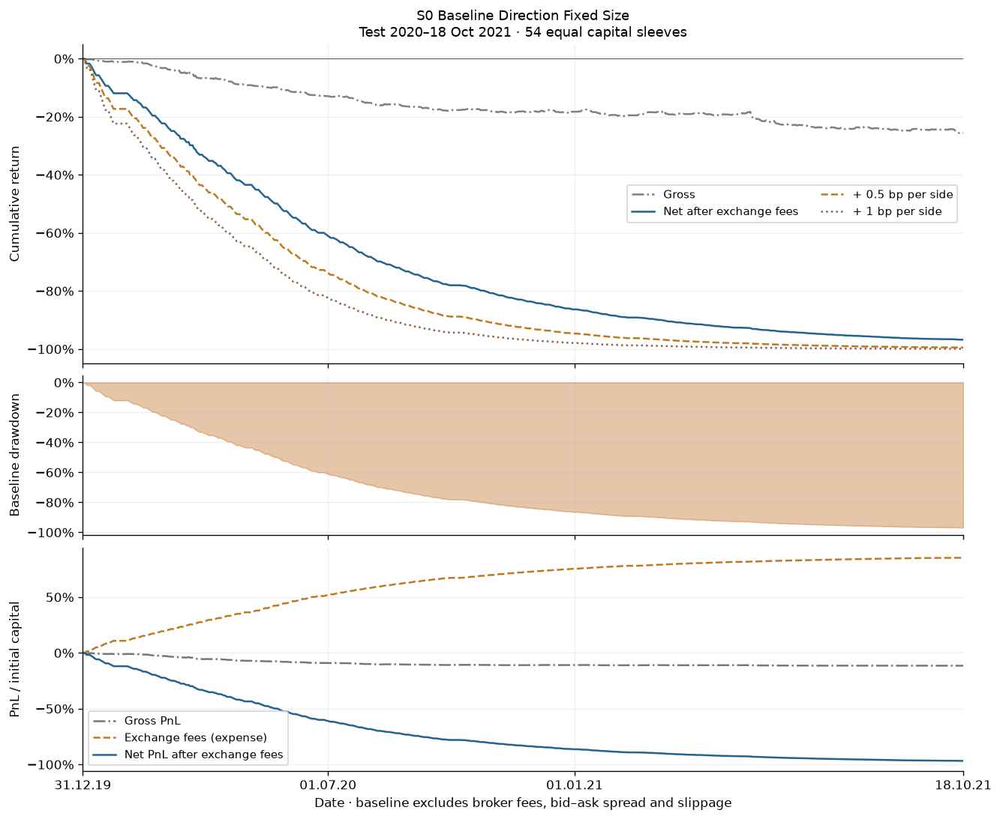

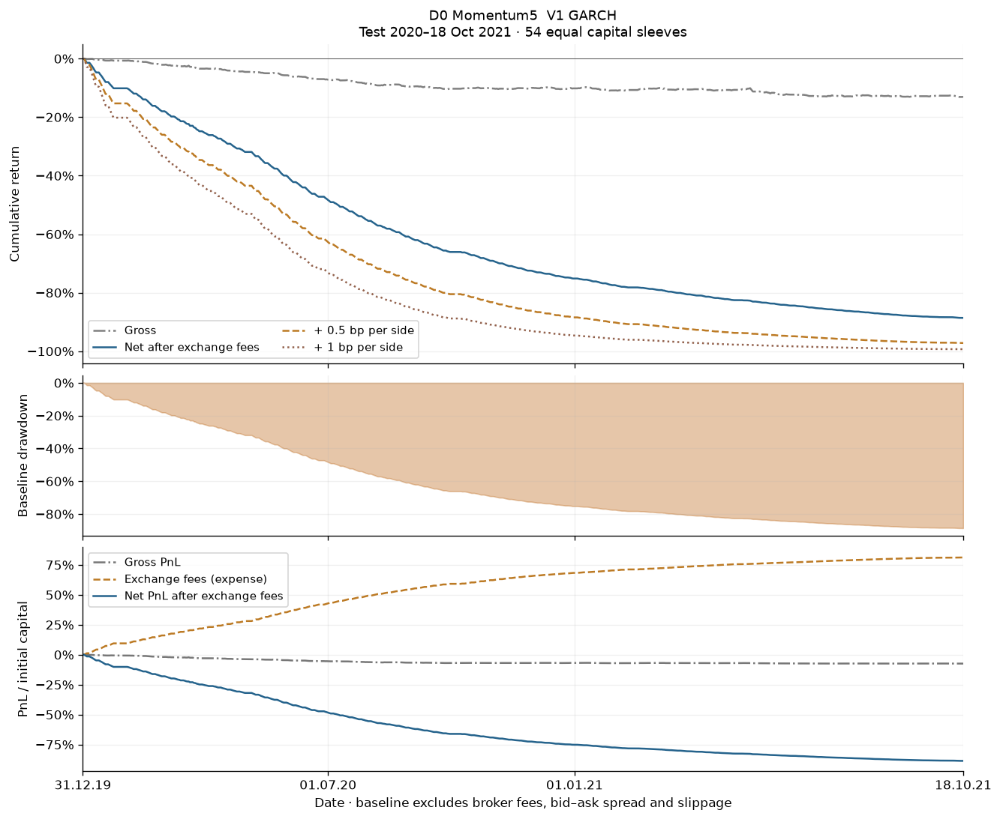

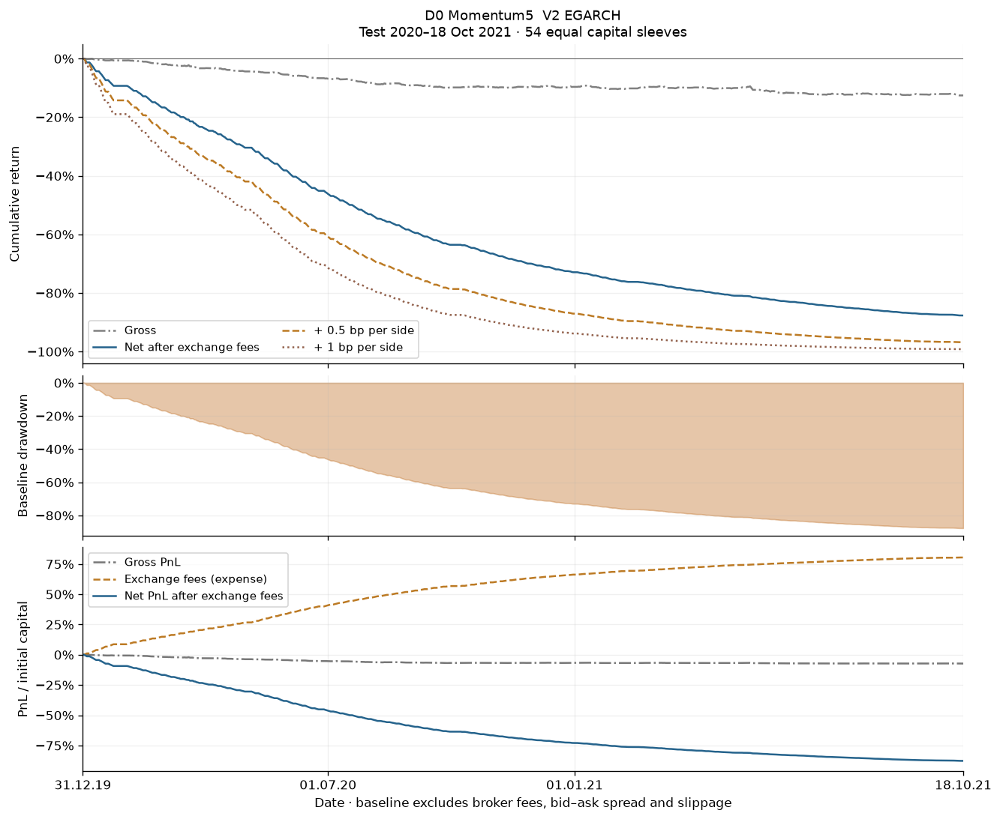

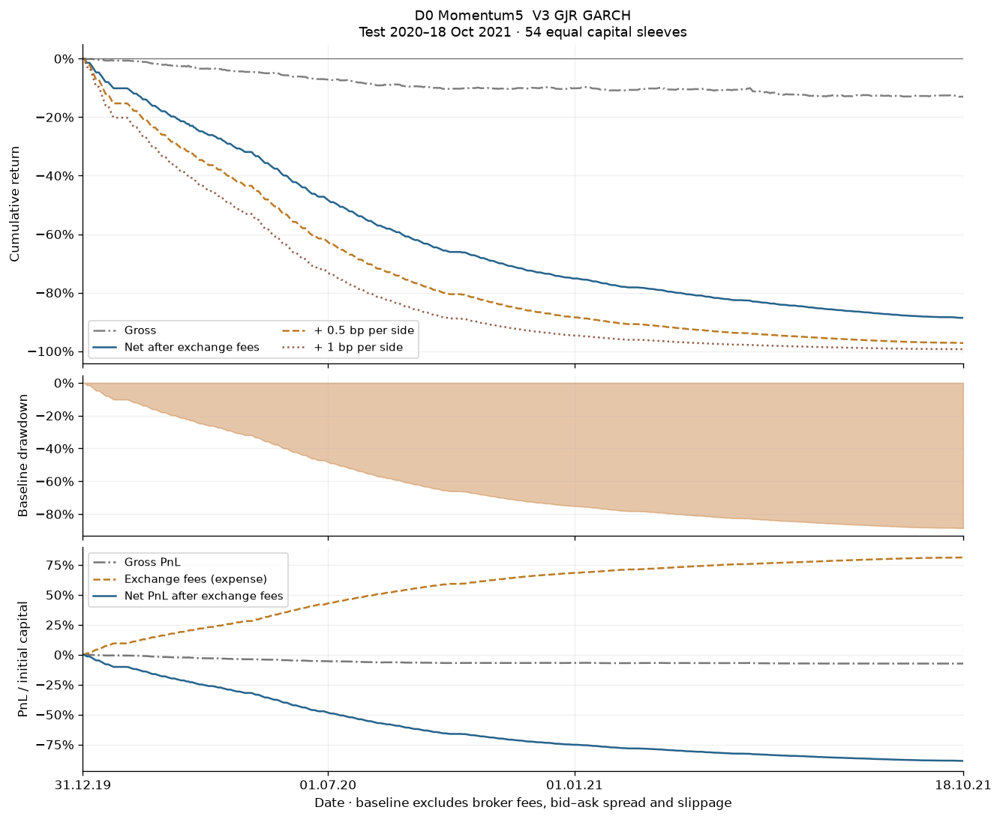

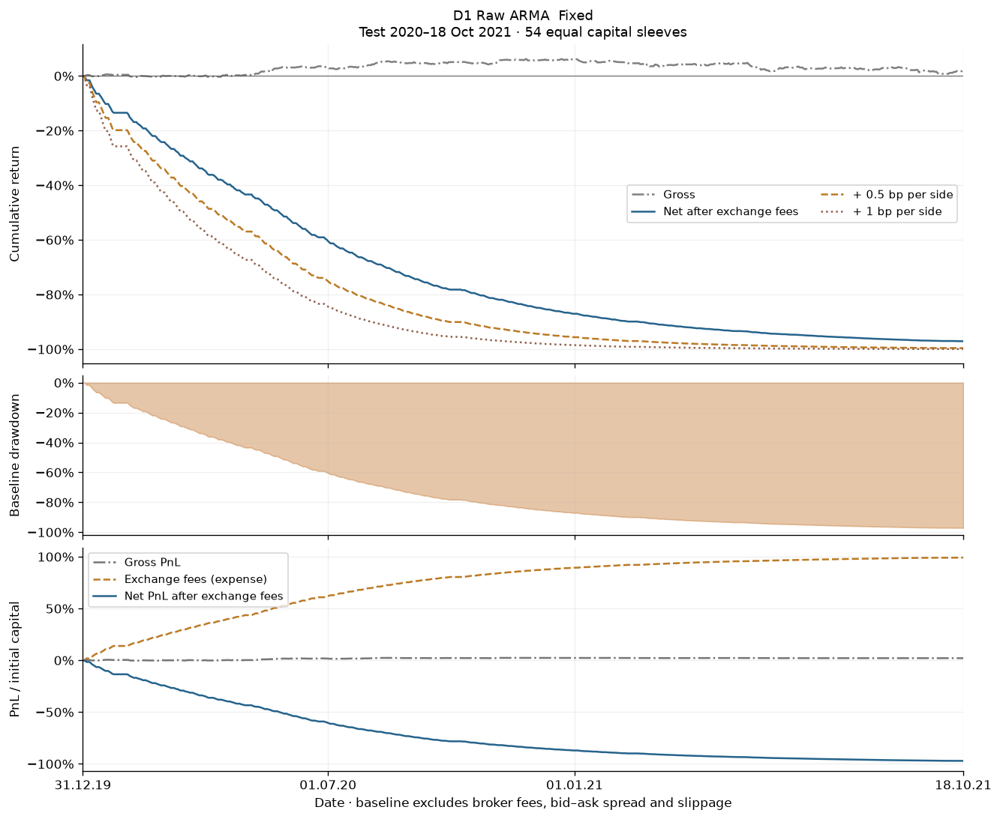

...

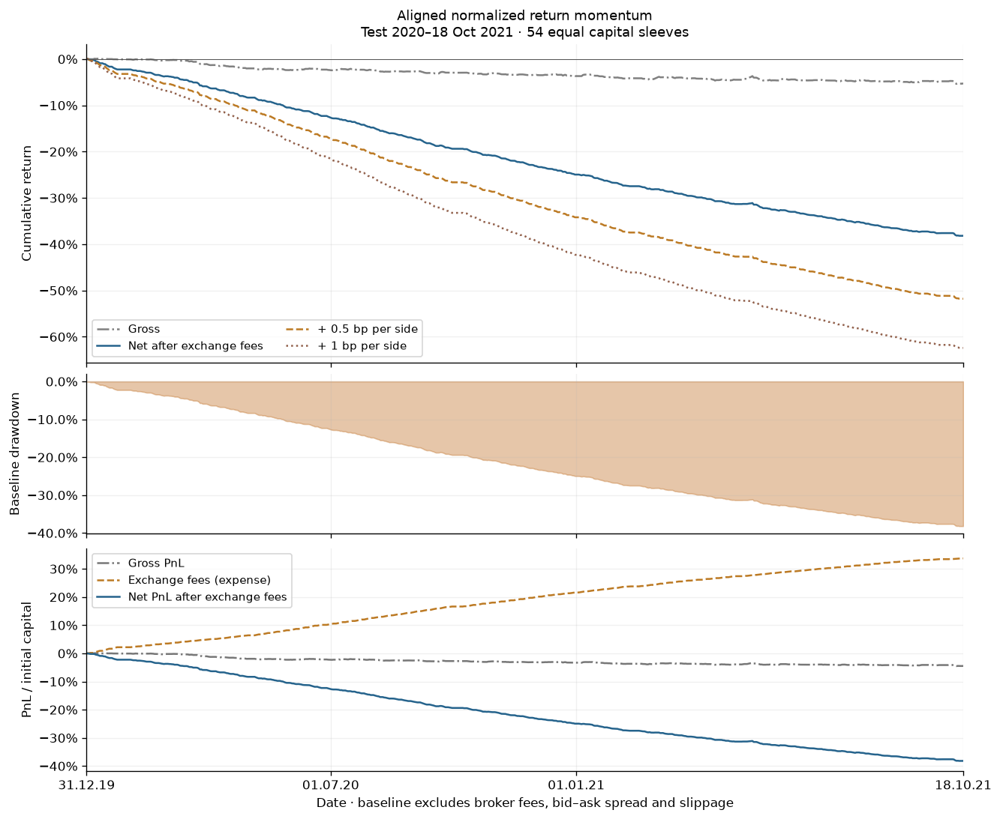

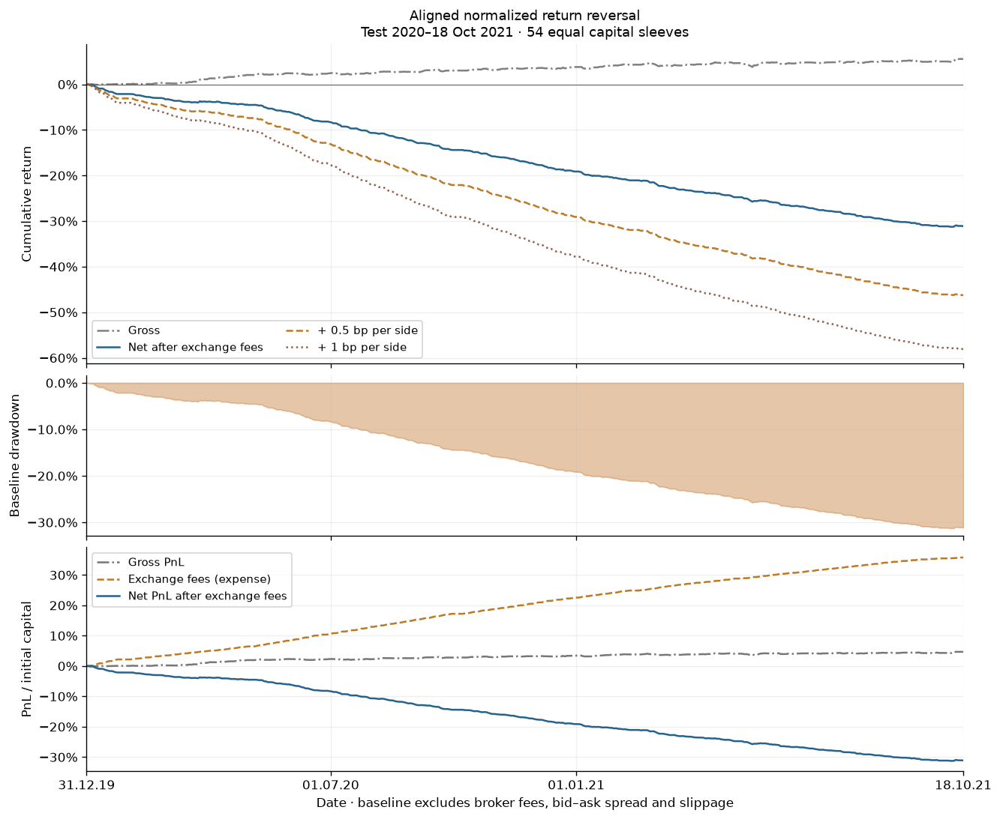

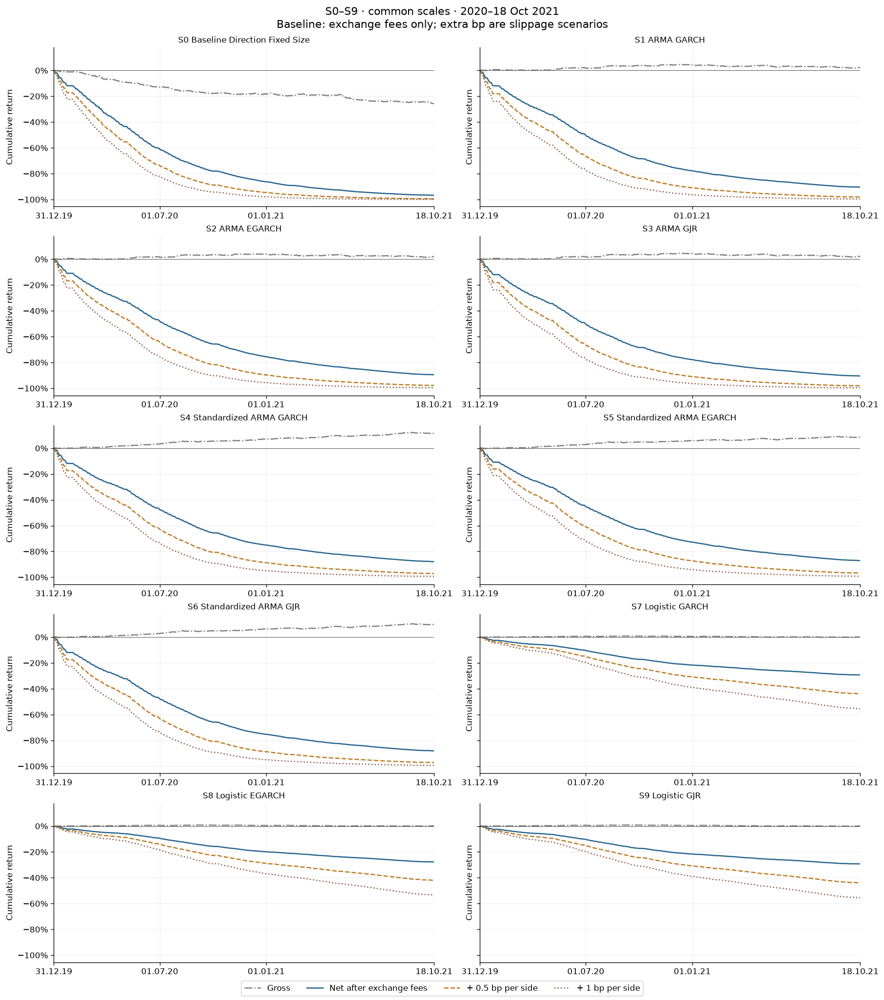

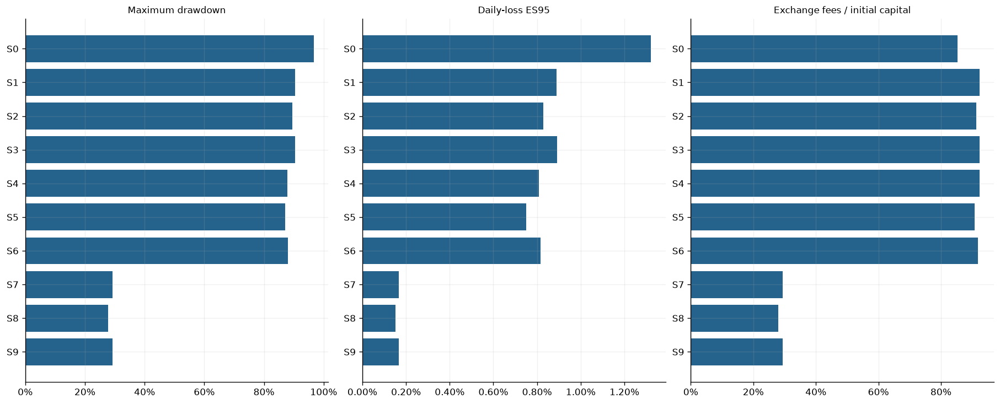

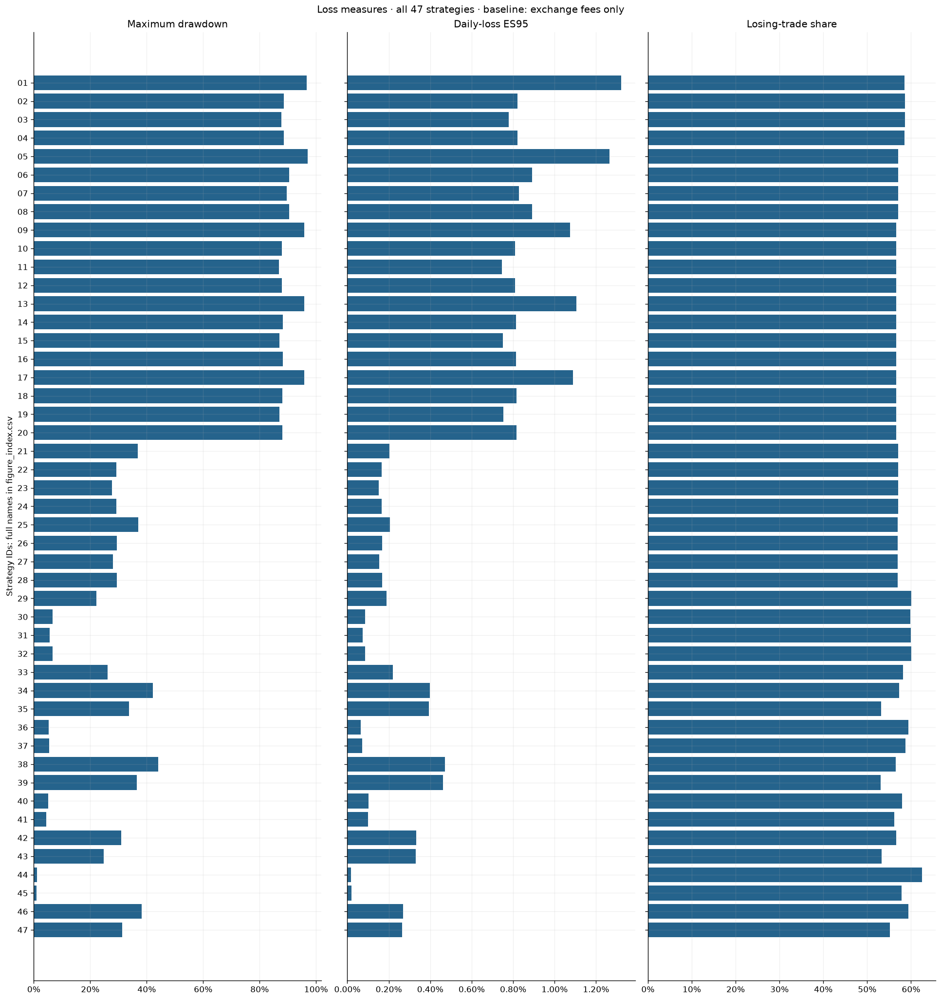

strategy,maximum_drawdown,longest_drawdown_calendar_days,worst_day,daily_var95,daily_es95,annualized_downside_deviation,losing_trade_share
S0_Baseline_Direction_Fixed_Size,0.96763,656,-0.02352,0.01126,0.01322,0.12901,0.58571
D0_Momentum5__V1_GARCH,0.88608,656,-0.00952,0.00758,0.00821,0.08214,0.58572
D0_Momentum5__V2_EGARCH,0.87677,656,-0.00982,0.00707,0.00780,0.07866,0.58572
D0_Momentum5__V3_GJR_GARCH,0.88601,656,-0.00952,0.00757,0.00821,0.08212,0.58571
D1_Raw_ARMA__Fixed,0.97089,656,-0.01574,0.01146,0.01265,0.13129,0.57074
S1_ARMA_GARCH,0.90458,656,-0.01000,0.00822,0.00891,0.08861,0.57073
S2_ARMA_EGARCH,0.89538,656,-0.00921,0.00766,0.00829,0.08455,0.57073
S3_ARMA_GJR,0.90466,656,-0.01000,0.00822,0.00891,0.08864,0.57073
D2_GARCH_ARMA__Fixed,0.95761,656,-0.01239,0.00979,0.01075,0.11653,0.56598
S4_Standardized_ARMA_GARCH,0.87925,656,-0.00999,0.00746,0.00809,0.07960,0.56597


strategy,total_return,maximum_drawdown,trades,active_files
S0_Baseline_Direction_Fixed_Size,-0.92672,0.92672,703400,46
S1_ARMA_GARCH,-0.85429,0.85429,792764,46
S2_ARMA_EGARCH,-0.84029,0.84029,792764,46
S3_ARMA_GJR,-0.85438,0.85438,792764,46
S4_Standardized_ARMA_GARCH,-0.84029,0.84029,792764,46
S5_Standardized_ARMA_EGARCH,-0.82826,0.82826,792764,46
S6_Standardized_ARMA_GJR,-0.84264,0.84264,792764,46
S7_Logistic_GARCH,-0.29251,0.29251,792764,46
S8_Logistic_EGARCH,-0.27729,0.27729,792764,46
S9_Logistic_GJR,-0.29276,0.29276,792764,46


strategy,AG_near_month_all,all_ratio_literal_1000,all_ratio_notes_10000,exchange_only,slippage_0.5bp_side,slippage_1bp_side
S0_Baseline_Direction_Fixed_Size,-0.97992,-0.99971,-0.95242,-0.96763,-0.99457,-0.99910
D0_Momentum5__V1_GARCH,-0.92719,-0.99485,-0.85872,-0.88608,-0.97203,-0.99316
D0_Momentum5__V2_EGARCH,-0.92185,-0.99374,-0.84942,-0.87677,-0.96825,-0.99186
D0_Momentum5__V3_GJR_GARCH,-0.92715,-0.99485,-0.85863,-0.88601,-0.97202,-0.99316
D1_Raw_ARMA__Fixed,-0.98288,-0.99981,-0.95517,-0.97089,-0.99611,-0.99948
S1_ARMA_GARCH,-0.94293,-0.99656,-0.87808,-0.90458,-0.98092,-0.99621
S2_ARMA_EGARCH,-0.93787,-0.99571,-0.86853,-0.89538,-0.97785,-0.99534
S3_ARMA_GJR,-0.94299,-0.99657,-0.87816,-0.90466,-0.98094,-0.99621
D2_GARCH_ARMA__Fixed,-0.97506,-0.99961,-0.93761,-0.95761,-0.99259,-0.99872
S4_Standardized_ARMA_GARCH,-0.92776,-0.99479,-0.84959,-0.87925,-0.97115,-0.99314


In [20]:
if RUN_BACKTEST:
    view=metrics.loc[metrics.cohort=='available']
    show(view[['strategy','total_return','gross_total_return','maximum_drawdown','sharpe','trades','active_files']], "Strategy performance and coverage",47)
    colors={'exchange_only':'#25638c','slippage_0.5bp_side':'#bc7a24','slippage_1bp_side':'#92614c'}
    labels={'exchange_only':'Net after exchange fees','slippage_0.5bp_side':'+ 0.5 bp per side','slippage_1bp_side':'+ 1 bp per side'}
    line_styles={'exchange_only':'-','slippage_0.5bp_side':'--','slippage_1bp_side':':'}
    date_ticks=pd.to_datetime(['2019-12-31','2020-07-01','2021-01-01','2021-10-18'])
    def draw_equity(ax,strategy,legend=False):
        p=portfolio.loc[(portfolio.strategy==strategy)&(portfolio.cohort=='available')]
        dates=pd.DatetimeIndex([SPLIT-pd.Timedelta(days=1),*p.day])
        ax.plot(dates,np.r_[0.,p.gross_equity.to_numpy()-1],color='#808080',ls='-.',label='Gross')
        for scenario in colors:
            part=scenario_curves.loc[(scenario_curves.strategy==strategy)&(scenario_curves.cohort=='available')&(scenario_curves.scenario==scenario)]
            ax.plot(dates,np.r_[0.,part.equity.to_numpy()-1],color=colors[scenario],ls=line_styles[scenario],label=labels[scenario])
        ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_xlim(dates[0],dates[-1]);ax.axhline(0,color='#555',lw=.6)
        ax.set_xticks(date_ticks,['31.12.19','01.07.20','01.01.21','18.10.21']);ax.set_ylabel("Cumulative return")
        if legend:ax.legend(ncol=2,fontsize=9,loc='best')
    for strategy in [s['strategy'] for s in specifications]:
        part=portfolio.loc[(portfolio.strategy==strategy)&(portfolio.cohort=='available')].set_index('day')
        dates=pd.DatetimeIndex([SPLIT-pd.Timedelta(days=1),*part.index])
        fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True,layout='constrained',gridspec_kw={'height_ratios':[2,1,1.4]})
        draw_equity(axes[0],strategy,True)
        axes[0].set_title(strategy.replace('_',' ')+"\nTest 2020–18 Oct 2021 · 54 equal capital sleeves",fontsize=11)
        axes[1].fill_between(dates,np.r_[0.,part.drawdown.to_numpy()],0,color='#c17229',alpha=.4,label='Base drawdown')
        axes[1].set_ylabel("Baseline drawdown");axes[1].yaxis.set_major_formatter(PercentFormatter(1))
        prior=np.r_[1.,part.equity.to_numpy()[:-1]]
        gross=np.cumsum(prior*part.gross.to_numpy());exchange=np.cumsum(prior*(part.exchange_open+part.exchange_close).to_numpy())
        net=gross-exchange
        np.testing.assert_allclose(net,part.equity.to_numpy()-1,atol=1e-9)
        for values,color,style,label in [(gross,'#777','-.','Gross PnL'),(exchange,'#bc7a24','--','Exchange fees (expense)'),(net,'#25638c','-','Net PnL after exchange fees')]:
            axes[2].plot(dates,np.r_[0.,values],color=color,ls=style,label=label)
        axes[2].set_ylabel("PnL / initial capital");axes[2].yaxis.set_major_formatter(PercentFormatter(1));axes[2].legend(ncol=1,fontsize=9)
        axes[2].set_xlabel("Date · baseline excludes broker fees, bid–ask spread and slippage")
        savefig(fig,'strategy_'+strategy)
    primary_names=[s for s,_,_ in PRIMARY]
    fig,axes=plt.subplots(5,2,figsize=(15,17),layout='constrained',sharey=True)
    for ax,strategy in zip(axes.flat,primary_names):
        draw_equity(ax,strategy);ax.set_title(strategy.replace('_',' '),fontsize=10)
    handles,leglabels=axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,leglabels,loc='outside lower center',ncol=4)
    fig.suptitle("S0–S9 · common scales · 2020–18 Oct 2021\nBaseline: exchange fees only; extra bp are slippage scenarios",fontsize=13)
    savefig(fig,'primary_equity_overview')
    pv=view.set_index('strategy').reindex(primary_names)
    fig,axes=plt.subplots(1,3,figsize=(15,6),layout='constrained')
    ticks=[n.split('_')[0] for n in pv.index]
    for ax,col,title in zip(axes,['maximum_drawdown','daily_es95','costs_contribution'],["Maximum drawdown","Daily-loss ES95","Exchange fees / initial capital"]):
        ax.barh(ticks,pv[col],color='#25638c');ax.invert_yaxis();ax.set_title(title,fontsize=10);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.axvline(0,color='#444',lw=.8)
    savefig(fig,'primary_loss_comparison')
    loss_columns=['strategy','maximum_drawdown','longest_drawdown_calendar_days','worst_day','daily_var95','daily_es95','annualized_downside_deviation','losing_trade_share','average_losing_trade','worst_trade','profit_factor','exchange_open_contribution','exchange_close_contribution','broker_contribution','slippage_contribution']
    view[loss_columns].to_csv(OUT/'loss_and_cost_metrics.csv',index=False)
    # All 47 strategies, stable registry order; SNN label maps to full strategy_registry.
    registry=pd.DataFrame(specifications)[['strategy']].assign(chart_id=[f'{i+1:02d}' for i in range(47)])
    registry.to_csv(OUT/'figure_index.csv',index=False)
    risk=view.set_index('strategy').reindex(registry.strategy)
    fig,axes=plt.subplots(1,3,figsize=(16,17),layout='constrained',sharey=True)
    for ax,col,title in zip(axes,['maximum_drawdown','daily_es95','losing_trade_share'],["Maximum drawdown","Daily-loss ES95","Losing-trade share"]):
        ax.barh(registry.chart_id,risk[col],color='#25638c');ax.set_title(title);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.axvline(0,color='#444',lw=.7)
    axes[0].invert_yaxis();axes[0].set_ylabel("Strategy IDs: full names in figure_index.csv")
    fig.suptitle("Loss measures · all 47 strategies · baseline: exchange fees only")
    savefig(fig,'all_strategy_loss_metrics')
    show(view[loss_columns[:8]],"Separate loss measures",47)
    show(metrics.loc[metrics.cohort=='common',['strategy','total_return','maximum_drawdown','trades','active_files']], "S0–S9: common forecasts available at signal time",10)
    sensitivity_table=scenario_metrics.loc[scenario_metrics.cohort=='available'].pivot(index='strategy',columns='scenario',values='total_return').reindex([s['strategy'] for s in specifications])
    sensitivity_table.to_csv(OUT/'sensitivity_total_returns.csv')
    show(sensitivity_table.reset_index(),"Sensitivity: cumulative net return on unchanged trades",47)

## Ledger checks

In [21]:
if RUN_BACKTEST:
    assert len(files)==54 and len(fees)==54
    assert len(metrics.loc[metrics.cohort=='available'])==47
    assert len(scenario_metrics)==57*len(SCENARIOS)
    assert not (execution_audit.status==7).any()
    assert len(list((OUT/'trades').glob('*.parquet')))==54
    assert len(list((OUT/'figures').glob('strategy_*.png')))==47
    np.testing.assert_allclose(empirical_es(np.r_[np.zeros(19),1.],.95),1.)
    passed('ES95 uses exactly 5 percent tail mass, including tied loss observations')
    independent=[]
    for record in manifest['features']:
        file=record['file'];t=pd.read_parquet(OUT/'trades'/(Path(file).stem+'.parquet'))
        fee=resolved.loc[file]
        p=pd.read_parquet(ROOT/record['path'],columns=['date','close','volume','symbol'])
        needed=pd.DatetimeIndex(pd.concat([t.signal_time,t.entry_time,t.exit_time]).unique())
        market=p.loc[p.date.isin(needed)].set_index('date')
        assert market.index.is_unique
        for leg in ['signal','entry','exit']:
            match=market.loc[t[leg+'_time']]
            np.testing.assert_allclose(match.close.to_numpy(),t[leg+'_price'])
            if leg!='signal': assert (match.volume.to_numpy()>0).all()
        np.testing.assert_allclose(t.gross,t.position*(t.exit_price-t.entry_price)/t.signal_price,atol=1e-13)
        q_abs=np.abs(t.position)/(t.signal_price*fee.price_multiplier)
        open_cost=q_abs*(fee.open_fixed+t.entry_price*fee.price_multiplier*fee.open_rate)
        close_cost=q_abs*(fee.close_today_fixed+t.exit_price*fee.price_multiplier*fee.close_today_rate)
        np.testing.assert_allclose(t.exchange_open,open_cost,atol=1e-13)
        np.testing.assert_allclose(t.exchange_close,close_cost,atol=1e-13)
        np.testing.assert_allclose(t.net,t.gross-open_cost-close_cost,atol=1e-13)
        assert (t.broker==0).all() and (t.slippage==0).all()
        assert (t.entry_time-t.signal_time).eq(pd.Timedelta(minutes=1)).all()
        assert (t.exit_time-t.entry_time).ge(pd.Timedelta(minutes=5)).all()
        assert t.entry_time.dt.normalize().eq(t.exit_time.dt.normalize()).all()
        # A day-to-night jump would change the exchange trading day despite the same calendar date.
        assert not ((t.entry_time.dt.hour<18)&(t.exit_time.dt.hour>=18)).any()
        for _,g in t.groupby(['strategy','cohort'],sort=False):
            assert (g.entry_time.to_numpy()[1:]>g.exit_time.to_numpy()[:-1]).all()
        independent.append(dict(file=file,trades=len(t),delayed_exits=int(t.delayed_exit.sum()),maximum_holding_minutes=int(t.holding_minutes.max()),trades_sha256=digest(OUT/'trades'/(Path(file).stem+'.parquet')),model_cache_sha256=digest(MODEL_DIR/'by_file'/(Path(file).stem+'.json'))))
    passed('54-file independent trade ledger audit: raw prices, positive volume, timing, costs and overlap')
    ledger_audit=pd.DataFrame(independent);ledger_audit.to_csv(OUT/'ledger_validation_54.csv',index=False)
    pd.DataFrame(tests).to_csv(OUT/'engine_tests.csv',index=False)
    validation=dict(status='passed',files=54,strategies=47,scenarios=len(SCENARIOS),tests=len(tests),unresolved_entered_positions=0,
                    base_broker_fees_included=False,base_spread_included=False,base_slippage_included=False,
                    historical_fees_reconstructed=False,unverified_rate_symbols=['I'],pristine_holdout=False,
                    daily_reconciliation_max_error=float(np.max(np.abs(portfolio.gross-portfolio.exchange_open-portfolio.exchange_close-portfolio.net))))
    (OUT/'validation.json').write_text(json.dumps(validation,ensure_ascii=False,indent=2)+'\n')
    display(Markdown(f"""Ledgers of all **54 files** checked; unresolved lost positions: **0**. **{len(tests)} checks** passed. All **47** individual charts saved."""))

Ledgers of all **54 files** checked; unresolved lost positions: **0**. **21 checks** passed. All **47** individual charts saved.

## Save results

In [22]:
notebook_source=json.loads((ROOT/'08_backtest_fees_risk_54.ipynb').read_text())
code_hash=hashlib.sha256('\n'.join(''.join(c['source']) for c in notebook_source['cells'] if c['cell_type']=='code').encode()).hexdigest()
receipt=dict(code_sha256=code_hash,backtest_run=RUN_BACKTEST,files=files,train=['2016-01-01','2019-12-31'],test=['2020-01-01','2021-10-18'],
    fee_workbook_sha256=digest(WORKBOOK),feature_manifest_sha256=digest(FEATURE_MANIFEST),
    model_manifest_sha256=digest(MODEL_DIR/'manifest.json'),ratio_divisor=RATIO_DIVISOR,ratio_overrides=RATIO_DIVISOR_BY_SYMBOL,
    fee_period_mode=FEE_PERIOD_MODE,broker_cny_per_lot_side=BROKER_CNY_PER_LOT_SIDE,slippage_bps_per_side=SLIPPAGE_BPS_PER_SIDE,
    ag_rate_policy=AG_RATE_POLICY,target_vol=TARGET_VOL,max_leverage=MAX_LEVERAGE,logistic_threshold=.5,
    source_verification_sha256=digest(OUT/'inputs/fee_verification.json'),official_shfe_snapshot_sha256=digest(OUT/'inputs/shfe_settlement_20260803.json'),
    scenario_definitions=SCENARIOS,exit_buffer_minutes=6,unverified_fee_symbols=['I'],
    strategy_count=len(specifications),universe_is_retrospective=True,integer_lots=False,python=platform.python_version(),tests=tests)
(OUT/'manifest.json').write_text(json.dumps(safe_json(receipt),ensure_ascii=False,indent=2)+'\n')
if RUN_BACKTEST:
    primary=metrics.loc[(metrics.cohort=='available')&metrics.strategy.isin([s for s,_,_ in PRIMARY])]
    all_variants=metrics.loc[metrics.cohort=='available']
    gross_positive=int((all_variants.gross_total_return>0).sum()); net_positive=int((all_variants.total_return>0).sum())
    display(Markdown(f"""Calculated **{len(specifications)} strategies** on **54 products**. Positive net returns among S0–S9: **{int((primary.total_return>0).sum())}**. Across all 47 variants, positive gross: **{gross_positive}**; positive net: **{net_positive}**. Equity, risk and cost results are saved; products without composite models retain cash for the affected strategies."""))
else:
    display(Markdown(f"""Prepared **54/54 files**, **{len(specifications)} strategies**, fee/execution functions and **{len(tests)} checks**. Returns await explicit cost settings; unavailable results are not replaced by zero."""))

Calculated **47 strategies** on **54 products**. Positive net returns among S0–S9: **0**. Across all 47 variants, positive gross: **28**; positive net: **0**. Equity, risk and cost results are saved; products without composite models retain cash for the affected strategies.